In [99]:
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import matplotlib.colors as mcolors
import matplotlib.cm as cm
from pathlib import Path
import pandas as pd
import seaborn as sns
import numpy as np
%load_ext autoreload
%autoreload 2
from fwh_analysis import FWHDataset, FWHPlotter


def fft(dataset, col='P_obs', title="FFT Spectrum", max_freq=None, auto_scale=True):
    # Extract arrays
    if type(dataset) == pd.DataFrame:
        time = dataset['Time'].values
        pressure = dataset[col].values
    elif type(dataset) == FWHDataset:
        time = dataset.data['Time'].values
        pressure = dataset.data[col].values
    
    # Calculate sampling parameters
    dt = time[1] - time[0]
    N = len(time)
    
    # Compute Single-Sided FFT
    freqs = np.fft.rfftfreq(N, d=dt)
    fft_complex = np.fft.rfft(pressure)
    
    # Normalize amplitude
    amplitude = 2.0 / N * np.abs(fft_complex)
    amplitude[0] = amplitude[0] / 2
    # amplitude[0] = 0
    phases = np.angle(fft_complex)
    
    # --- DYNAMIC X-AXIS SCALING ---
    if auto_scale and max_freq is None:
        max_amp = np.max(amplitude)
        
        # Set threshold to 1% of the dominant peak. 
        # The 1e-3 acts as an absolute hard floor so numerical noise (1e-15) doesn't drag the axis to infinity.
        threshold = max(0.01 * max_amp, 1e-3) 
        
        # Find all array indices where the amplitude is greater than the threshold
        significant_indices = np.where(amplitude > threshold)[0]
        
        if len(significant_indices) > 0:
            # Get the frequency of the very last significant peak
            highest_significant_freq = freqs[significant_indices[-1]]
            # Add a 15% visual buffer to the right, capped at the Nyquist frequency
            max_freq = min(highest_significant_freq * 1.15, freqs[-1])
        else:
            max_freq = freqs[-1]  # Fallback if flatline

    # --- PLOTTING ---
    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(freqs, amplitude, linestyle='-', color='b', markersize=4)
    
    ax.set_title(title, weight='bold')
    ax.set_xlabel('Frequency (Hz)')
    ax.set_ylabel('Amplitude (Pa)')
    ax.grid(True, linestyle='--', alpha=0.6)
    
    if max_freq:
        ax.set_xlim(left=0, right=max_freq)
        
    plt.tight_layout()
    plt.show()
    
    return freqs, amplitude, phases

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


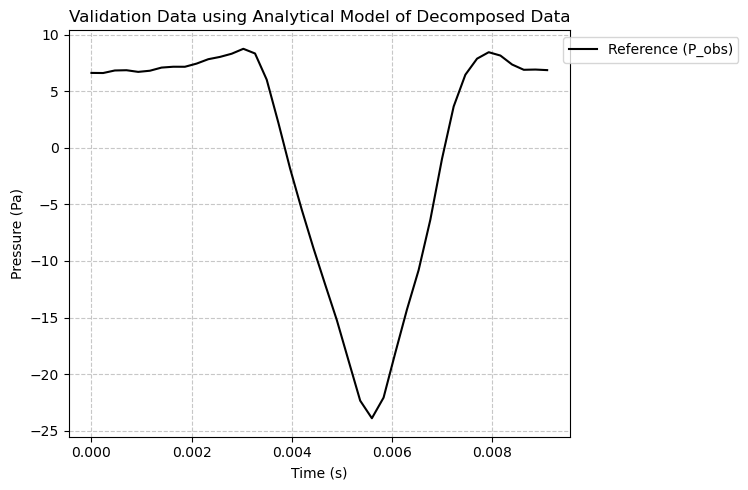

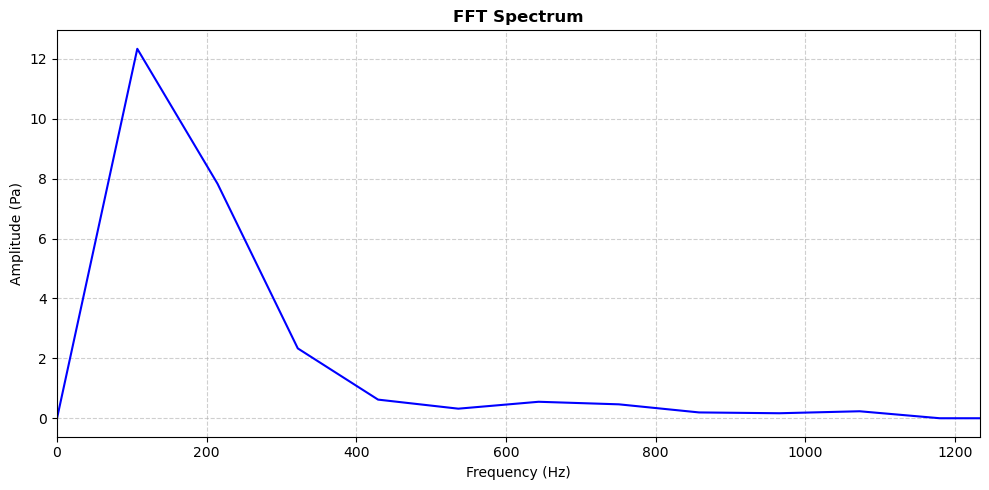

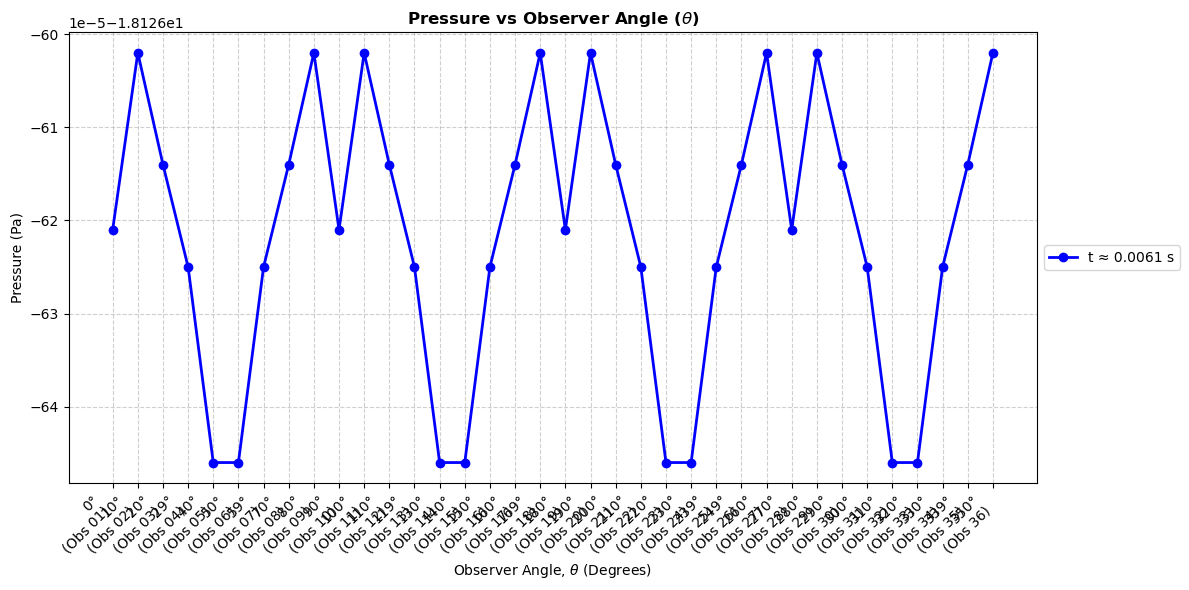

In [102]:
filepath = Path('data_260707/WoanGregorekValidation')
temporal_data = FWHDataset(filepath=filepath / 'ana_01.dat')
FWHPlotter.plot_pressure(temporal_data, ref_col='P_obs', title='Validation Data using Analytical Model of Decomposed Data')
fft(temporal_data)

obs_files = sorted(filepath.glob(f'ana_*.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]

FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=6e-3,
                                     col='P_obs',
                                     is_polar=False)

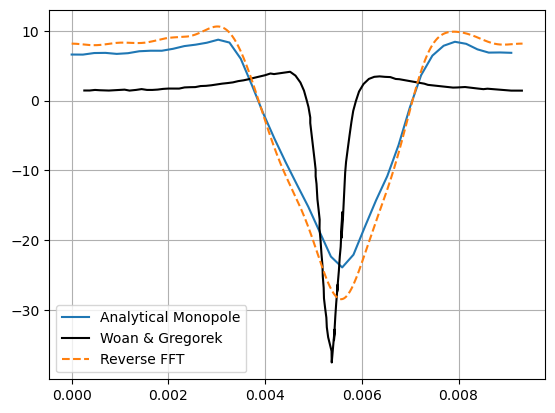

In [97]:
fig, ax = plt.subplots()
ax.plot(temporal_data.data['Time'],  temporal_data.data['P_obs'], label='Analytical Monopole')
ax.plot(ref_data_auto['Time'], ref_data_auto['P_obs'], label='Woan & Gregorek', c='black')
ax.plot(t, pressure, ls='--', label='Reverse FFT')
ax.grid(True)
ax.legend()
plt.show()

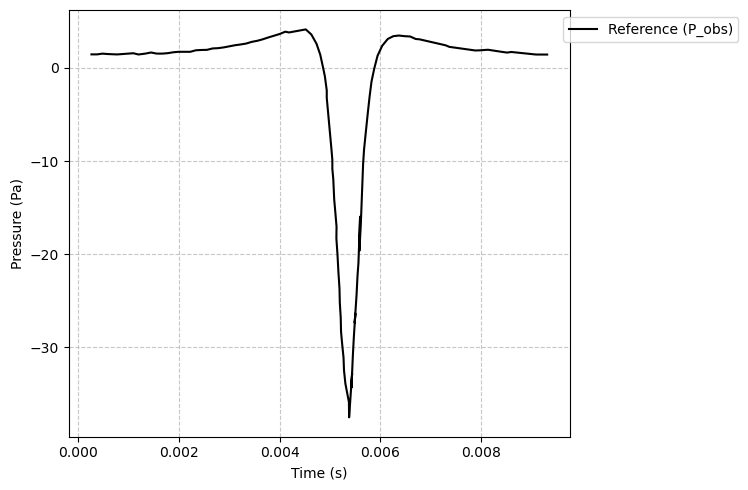

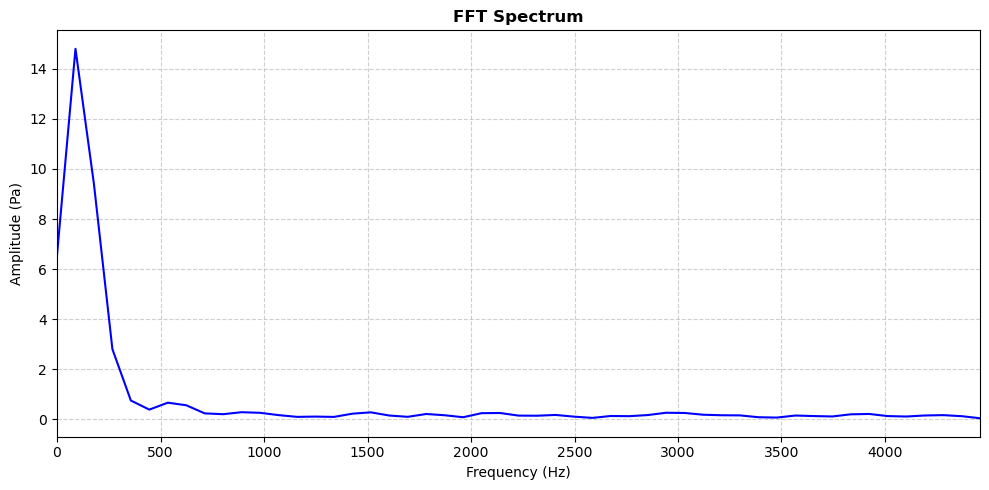

In [101]:
ref_data_auto = pd.read_csv('data_260706_REFERENCE/woan_gregorek_pt_auto_xtime.csv', names=['Time','P_obs'])
FWHPlotter.plot_pressure(ref_data_auto, ref_col='P_obs')
freq_amp = fft(ref_data_auto)
fft_data = pd.DataFrame({'Frequency':freq_amp[0], 'Amplitude':freq_amp[1], 'Phase':freq_amp[2],
              'Phase (deg)':np.rad2deg(freq_amp[2])})


In [48]:
ref_data_auto

,Time,P_obs
0,0.000262,1.456391
1,0.000373,1.454927
2,0.000484,1.536931
3,0.000586,1.492186
4,0.000771,1.449681
...,...,...
96,0.008515,1.648052
97,0.008598,1.713729
98,0.009088,1.440165
99,0.009162,1.439189


In [76]:
fft_data['Phase'].to_numpy()

array([ 3.14159265, -0.57408072,  2.01884969, -1.88204196, -1.04759197,
        1.8760436 , -0.33453731,  2.47233509, -1.40745429,  0.3626003 ,
        2.61284136, -1.3709246 ,  1.29914026, -1.51161962,  2.09586265,
       -2.20199569, -0.83433288,  1.57800546, -2.19064593, -1.66451827,
        0.75537279, -3.07799415, -2.73499062, -0.54495739,  1.86668983,
       -2.22460969, -0.98391827,  1.03687946, -2.64036316,  2.40460735,
       -1.06969258,  1.03351271,  2.38065262, -1.72683708,  0.69734007,
        2.55032164, -2.06269948,  0.157944  ,  2.2130902 ,  2.90415985,
       -1.5016545 ,  0.55749521,  2.03647801, -2.03065219,  0.42928607,
        2.77584543, -2.04324946,  0.43636296, -2.91896788, -0.16607542,
        2.39428765])

/tmp/ipykernel_416928/562639908.py:25: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  fig.show()


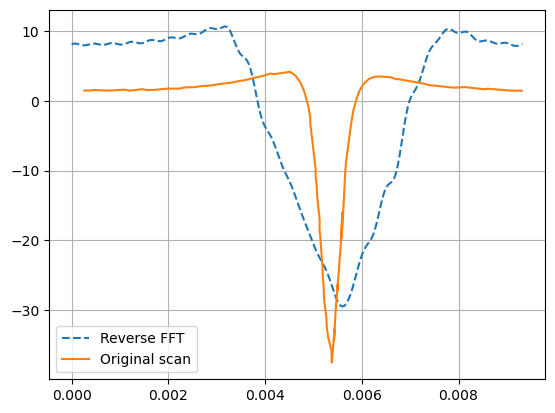

In [98]:
T_period = 9.324e-3
t = np.linspace(0, T_period, 500)
# p1 = fft_data['Amplitude'][1] * np.cos((2 * np.pi * fft_data['Frequency'][1] * t) + fft_data['Phase'][1])
# p2 = fft_data['Amplitude'][2] * np.cos((2 * np.pi * fft_data['Frequency'][2] * t) + fft_data['Phase'][2])
# p3 = fft_data['Amplitude'][3] * np.cos((2 * np.pi * fft_data['Frequency'][3] * t) + fft_data['Phase'][3])
# p4 = fft_data['Amplitude'][4] * np.cos((2 * np.pi * fft_data['Frequency'][4] * t) + fft_data['Phase'][4])
# p5 = fft_data['Amplitude'][5] * np.cos((2 * np.pi * fft_data['Frequency'][5] * t) + fft_data['Phase'][5])
# p6 = fft_data['Amplitude'][6] * np.cos((2 * np.pi * fft_data['Frequency'][6] * t) + fft_data['Phase'][6])
# p7 = fft_data['Amplitude'][7] * np.cos((2 * np.pi * fft_data['Frequency'][7] * t) + fft_data['Phase'][7])
# p8 = fft_data['Amplitude'][8] * np.cos((2 * np.pi * fft_data['Frequency'][8] * t) + fft_data['Phase'][8])
# pressure = p1 + p2 + p3 + p4 + p5 + p6 + p7 + p8
pressure = 0
for i in range(24):
    amp = fft_data['Amplitude'][i]
    # freq = fft_data['Frequency'][i]
    freq = i / T_period
    phase = fft_data['Phase'][i]
    pressure += amp * np.cos(2 * np.pi * freq * t + phase)

fig, ax = plt.subplots()
ax.plot(t, pressure, ls='--', label='Reverse FFT')
ax.plot(ref_data_auto['Time'], ref_data_auto['P_obs'], ls='-', label='Original scan')
ax.grid(True)
ax.legend()
fig.show()

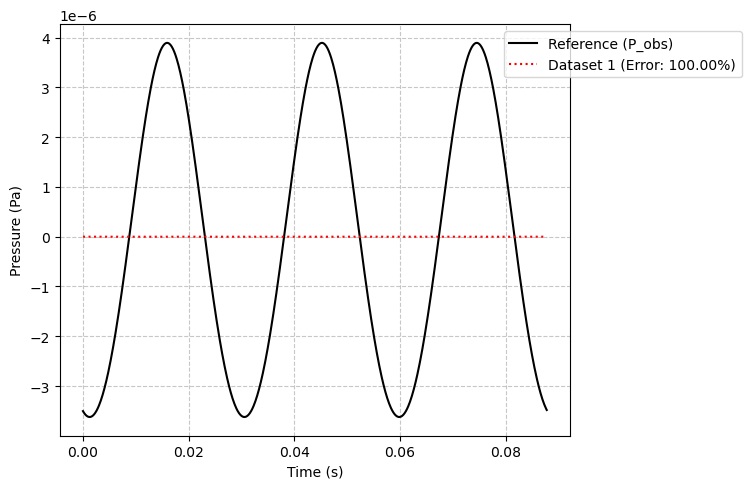

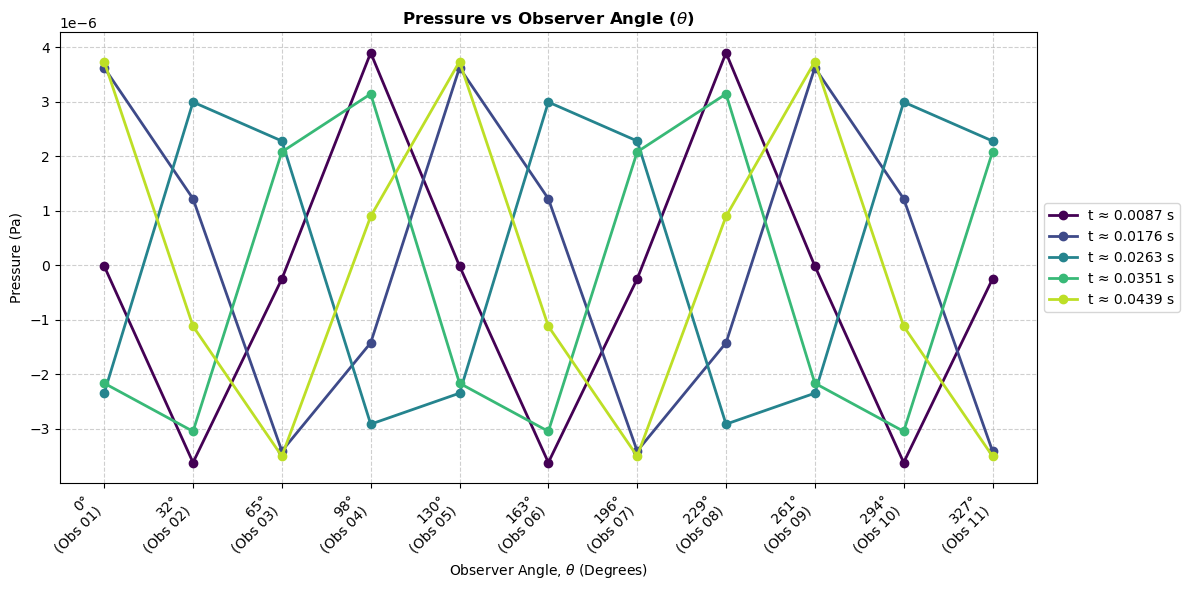

In [108]:
filepath = Path('data_260706/chordwise_3blades_50pts_71Hz/')
ana = FWHDataset(filepath / f"FWH_observer_time_02_validation.dat")
num = FWHDataset(filepath /"FWH_observer_time_01_RT.dat")
FWHPlotter.plot_pressure(ana, num, ref_col='P_obs', title=None, legend=True)

obs_files = sorted(filepath.glob(f'FWH_observer_time_*_validation.dat'))
datasets = [FWHDataset(filepath=f) for f in obs_files]
t_half = datasets[0].data['Time'].max() / 2

snapshot_times = np.linspace(t_half/5, t_half
                                 , num=5)
FWHPlotter.plot_directivity_snapshot(datasets=datasets,
                                     target_times=snapshot_times,
                                     col='P_obs',
                                     is_polar=False)

<class 'fwh_analysis.FWHDataset'>


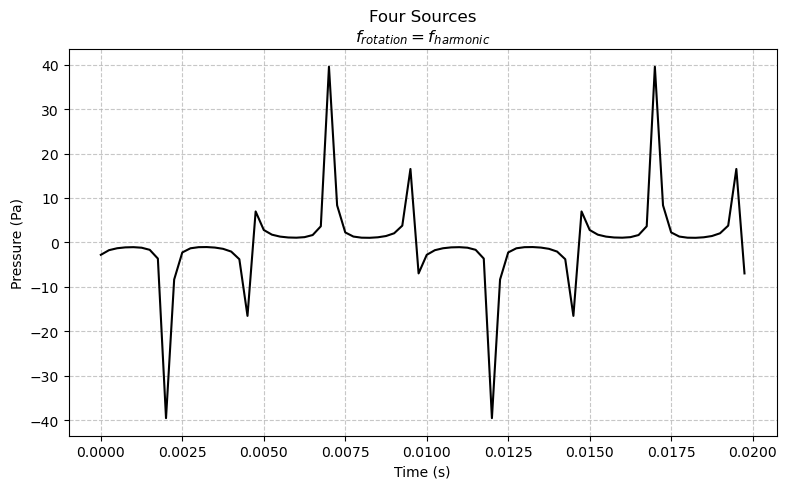

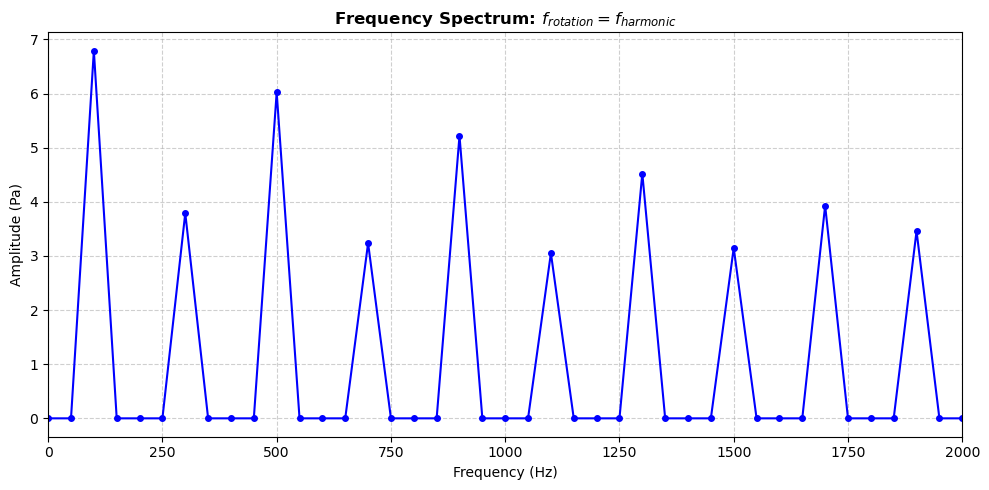

<class 'fwh_analysis.FWHDataset'>


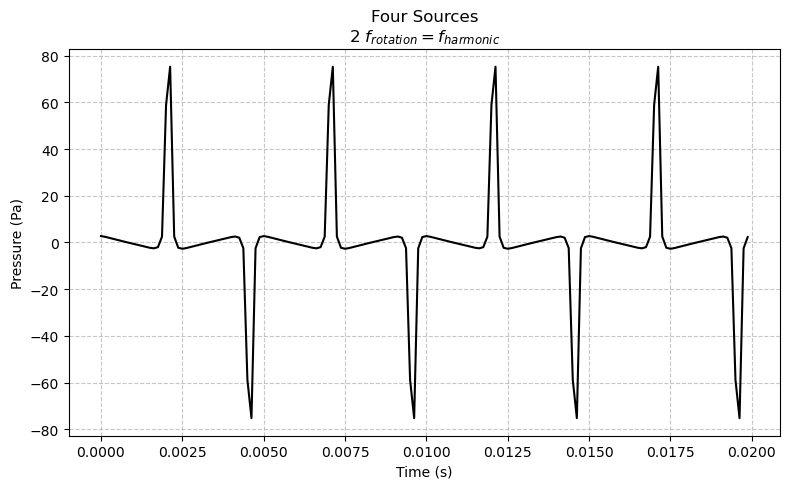

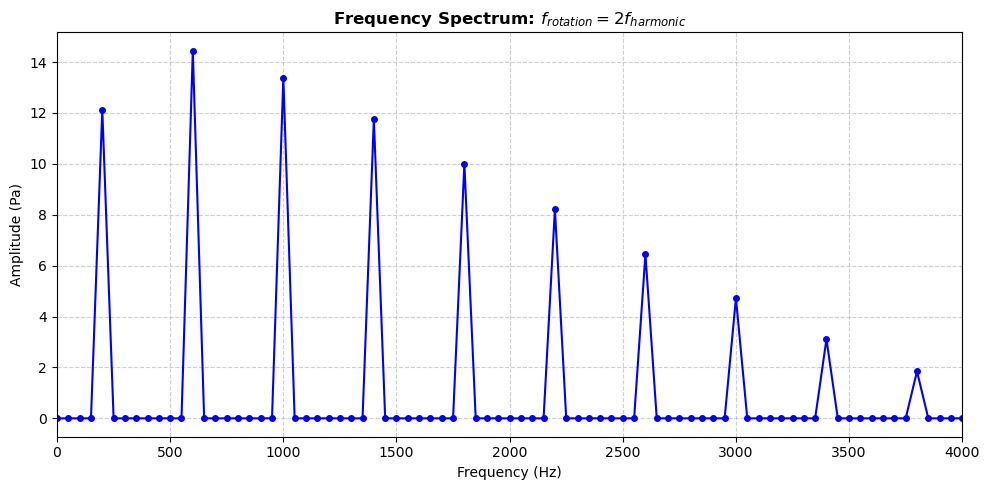

<class 'fwh_analysis.FWHDataset'>


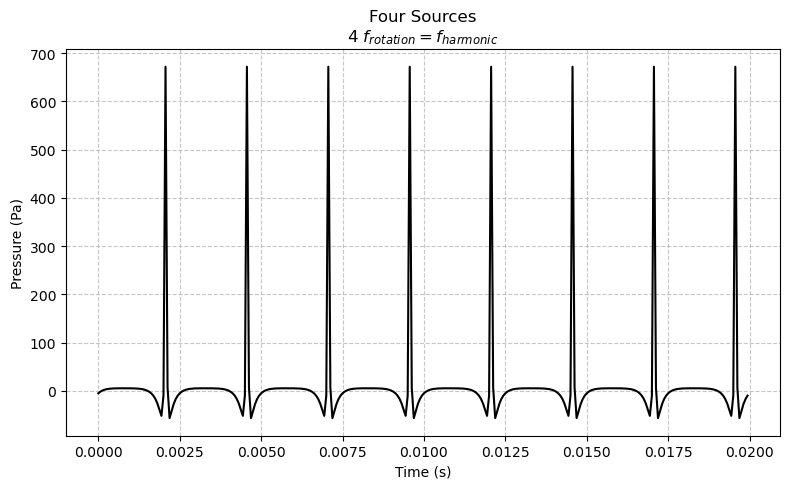

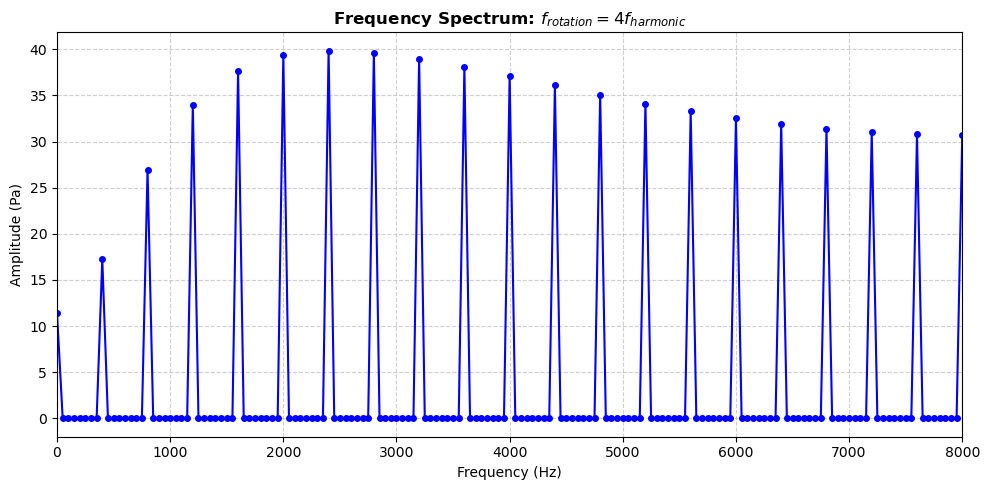

<class 'fwh_analysis.FWHDataset'>


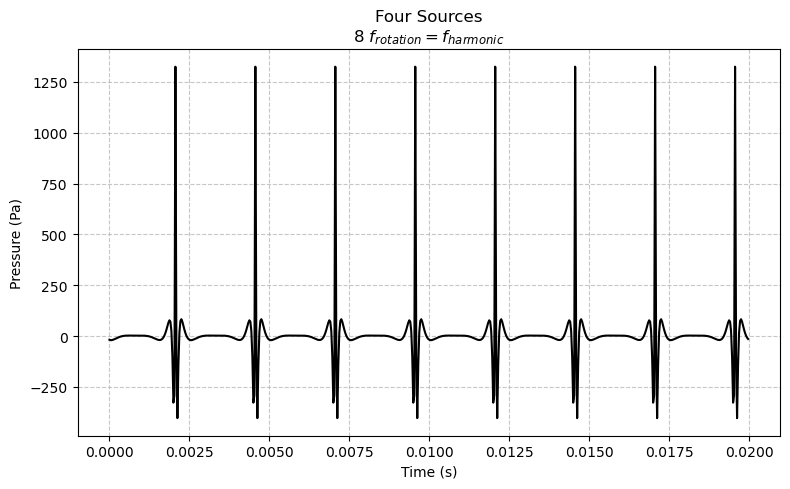

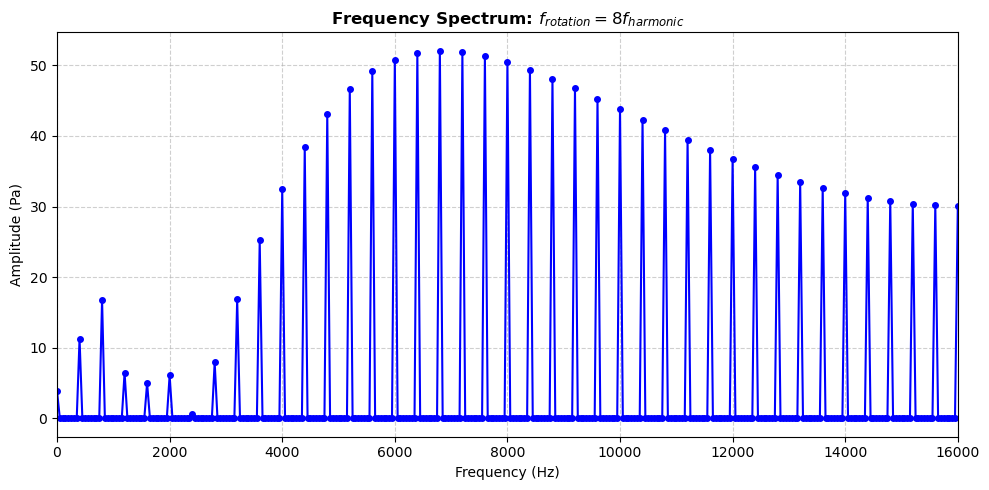

<class 'fwh_analysis.FWHDataset'>


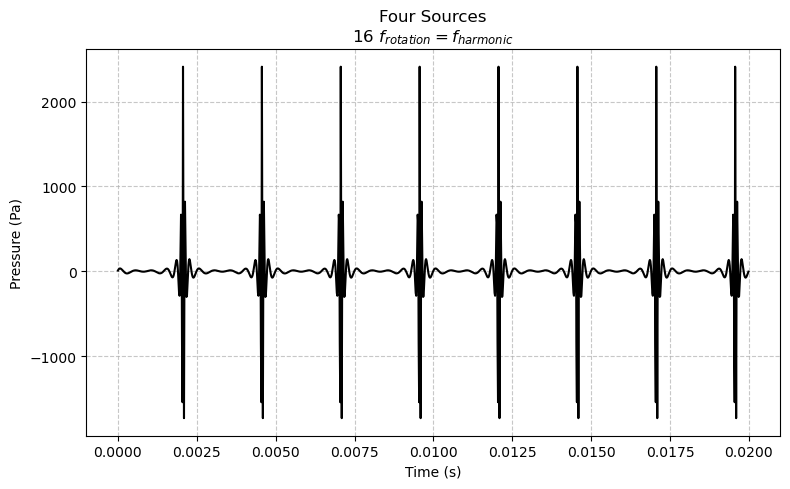

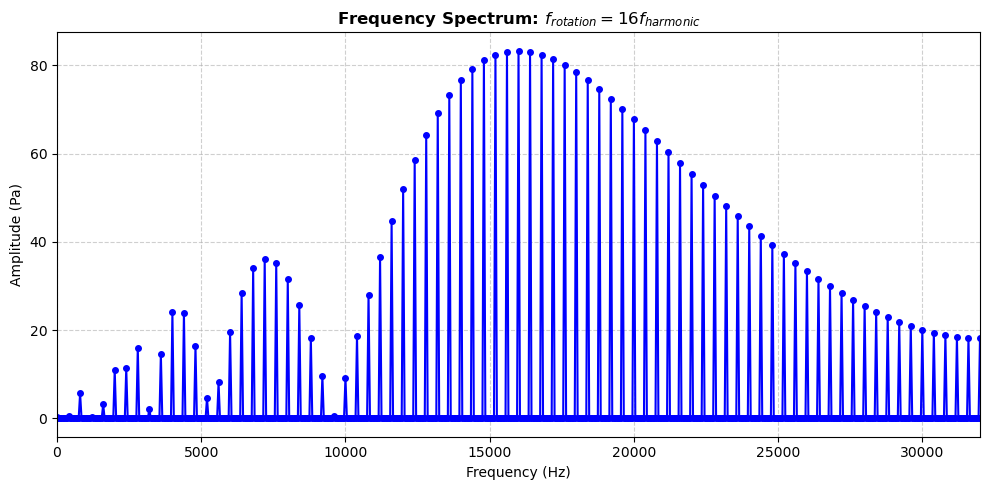

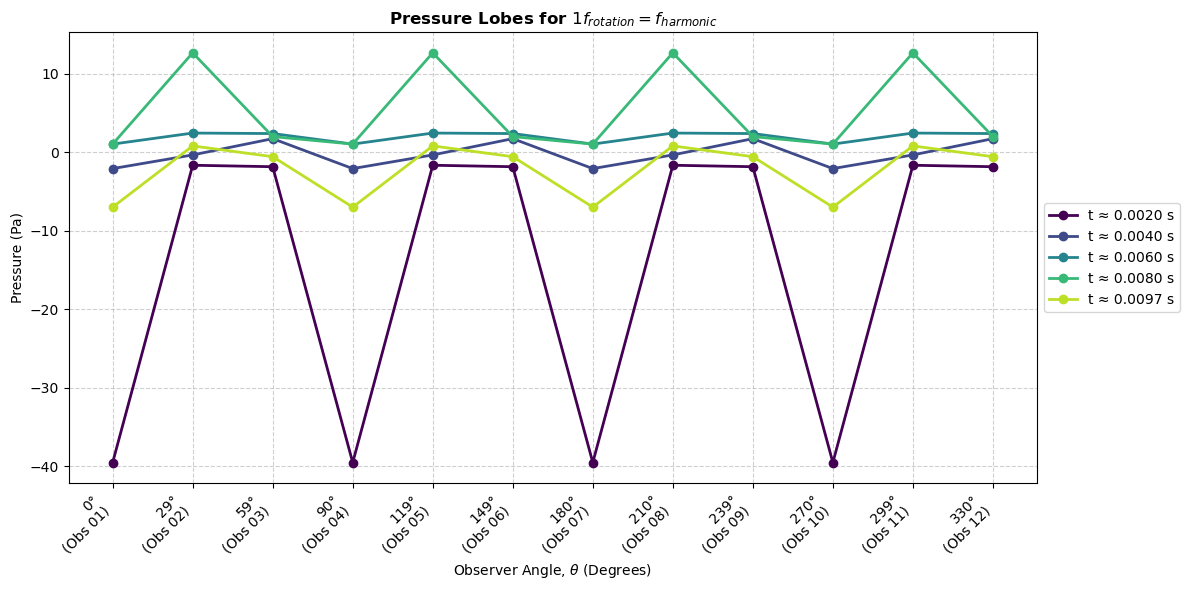

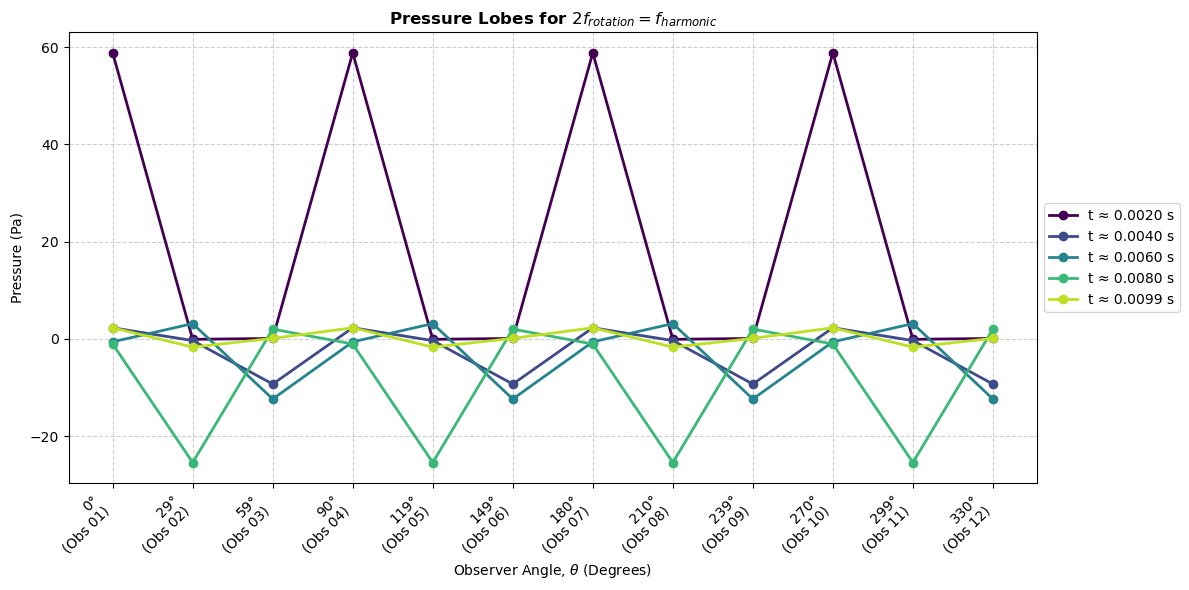

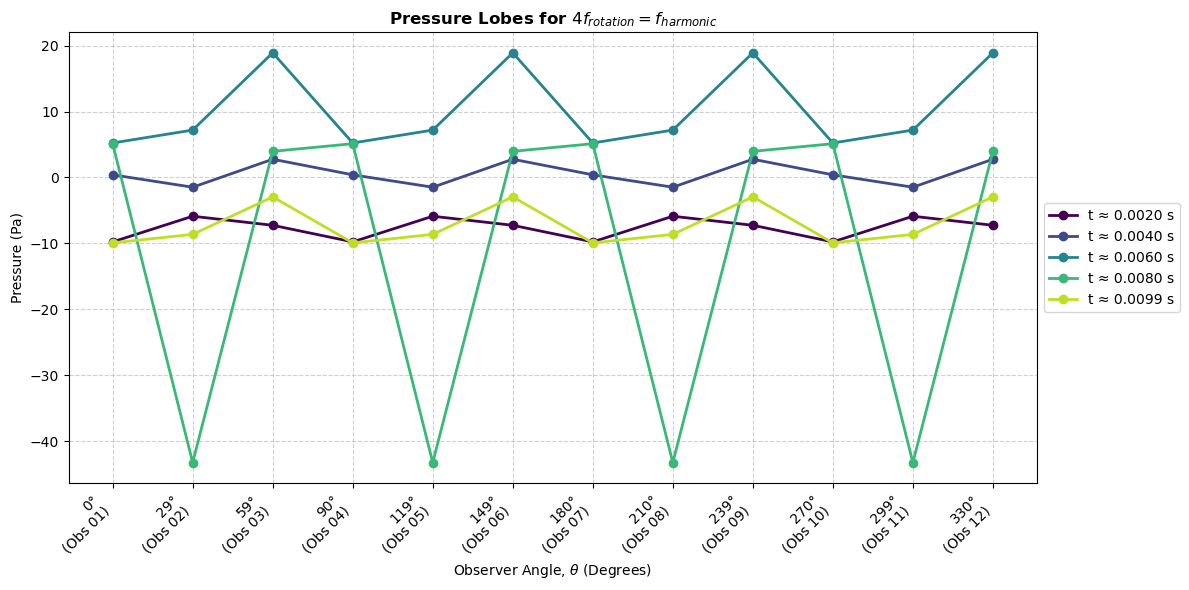

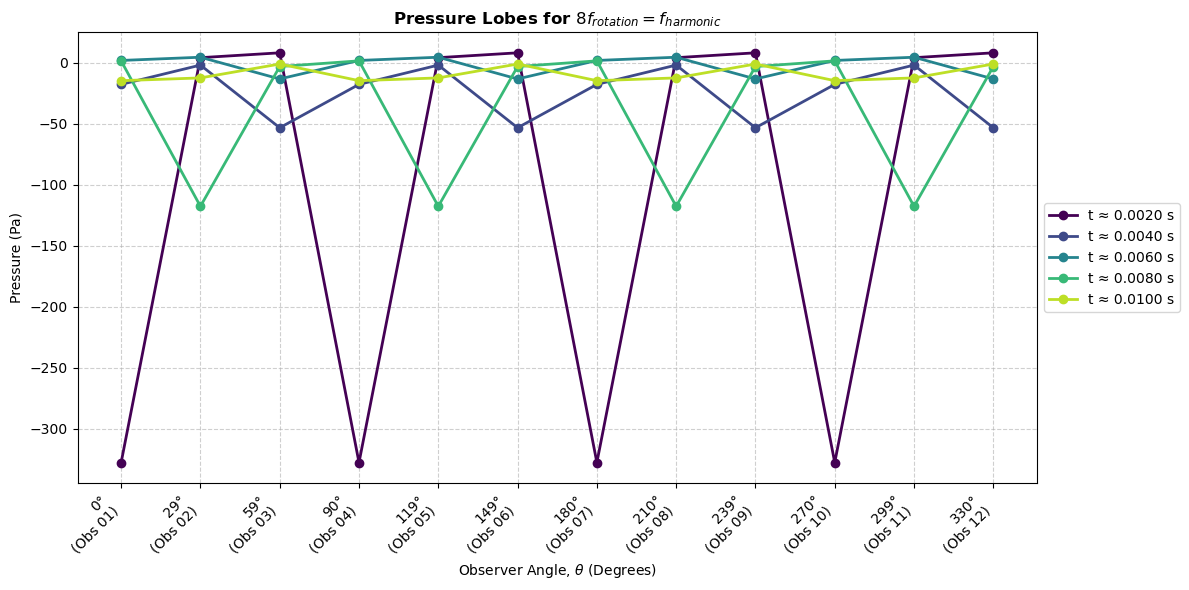

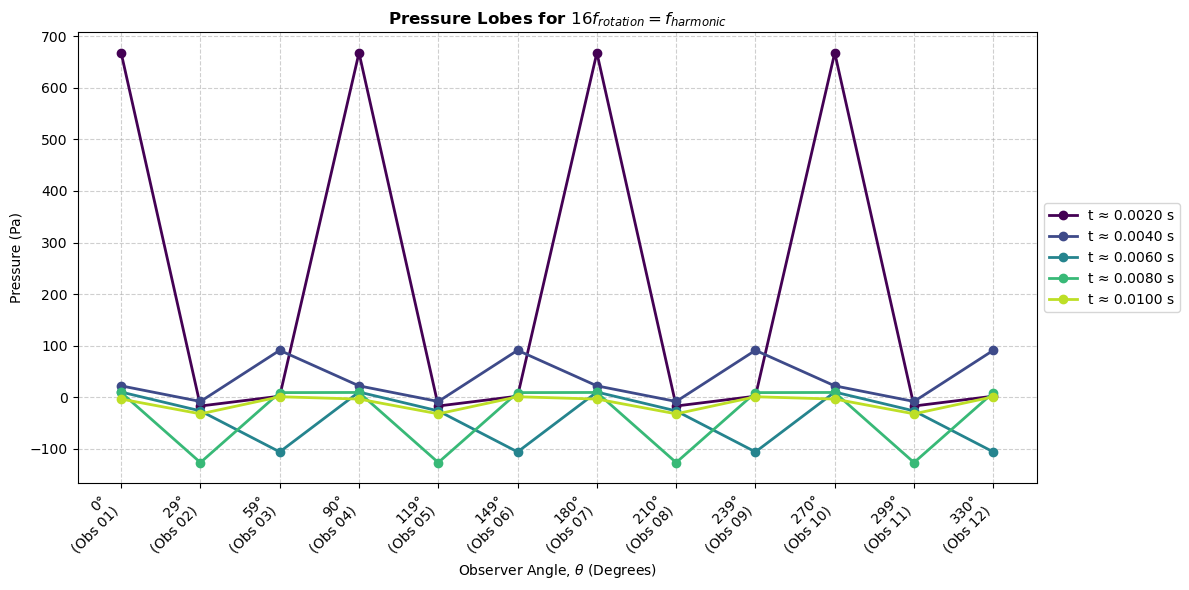

In [8]:
filepath = Path('data_260703/rot_mono_4src_00M_100Hz/')
freqs = (100, 200, 400, 800, 1600)

data = [FWHDataset(filepath=filepath / f'ana_rot_{i}Hz_obs01.dat') for i in freqs]

ratios = [1, 2, 4, 8, 16]
for i, dataset in enumerate(data):
    ratio = ratios[i]
    print(type(dataset))
    if ratio == 1:
        title_str = ("Four Sources" + "\n" + r"$f_{rotation} = f_{harmonic}$")
        fft_title = r"Frequency Spectrum: $f_{rotation} = f_{harmonic}$"
    else:
        title_str = ("Four Sources" + "\n" rf"{ratio} $f_{{rotation}} = f_{{harmonic}}$")
        fft_title = rf"Frequency Spectrum: $f_{{rotation}} = {ratio} f_{{harmonic}}$"
        
    FWHPlotter.plot_pressure(dataset, ref_col='P_obs', title=title_str, legend=False)
    fft(dataset, col='P_obs', title=fft_title)

for i in freqs:
    obs_files = sorted(filepath.glob(f"ana_rot_{i}Hz_obs*.dat"))
    datasets = [FWHDataset(filepath=f) for f in obs_files]

    t_half = datasets[0].data['Time'].max() / 2

    snapshot_times = np.linspace(t_half/5, t_half
                                 , num=5)

    FWHPlotter.plot_directivity_snapshot(
        datasets=datasets, 
        target_times=snapshot_times, 
        col='P_obs',
        is_polar=False,
        title=f"Pressure Lobes for $ {int(i/100)} f_{{rotation}} = f_{{harmonic}}$"
    )

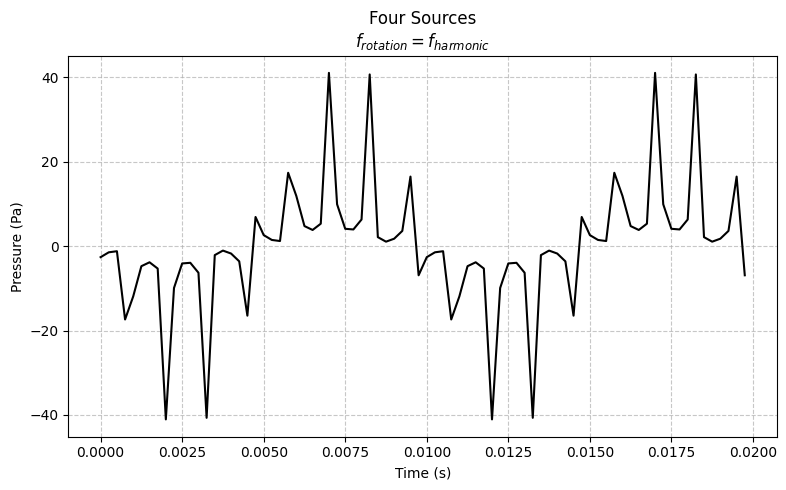

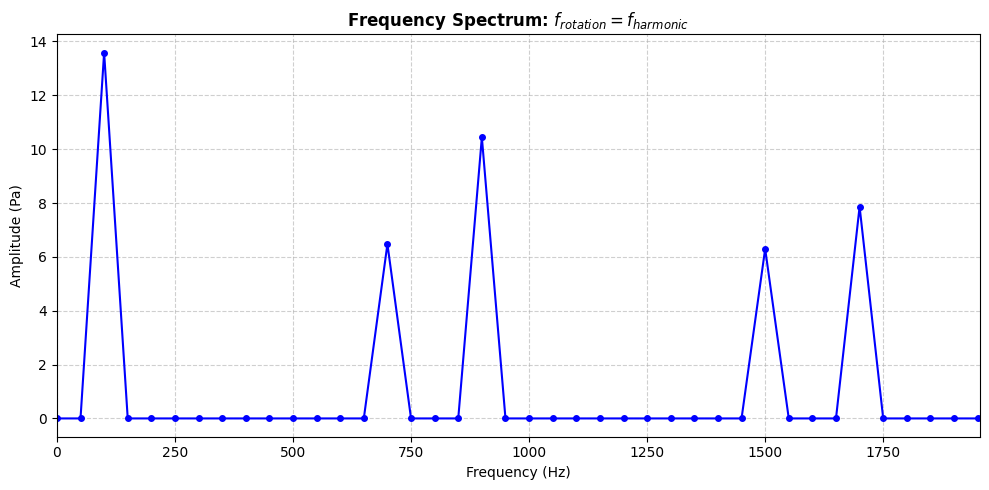

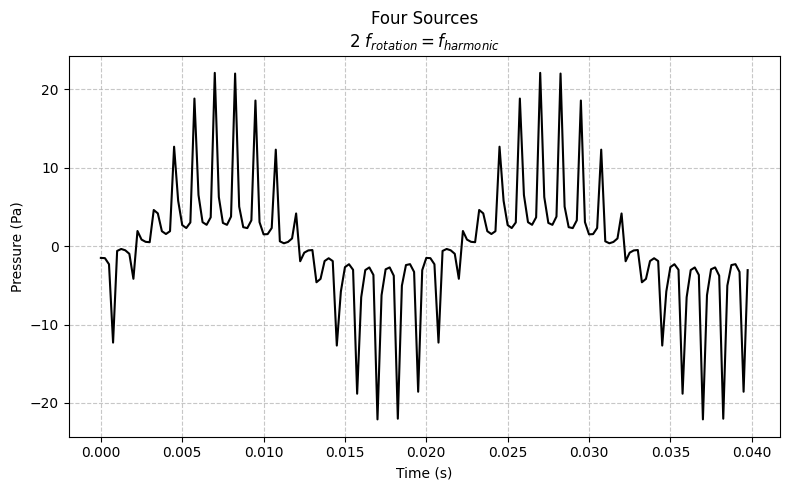

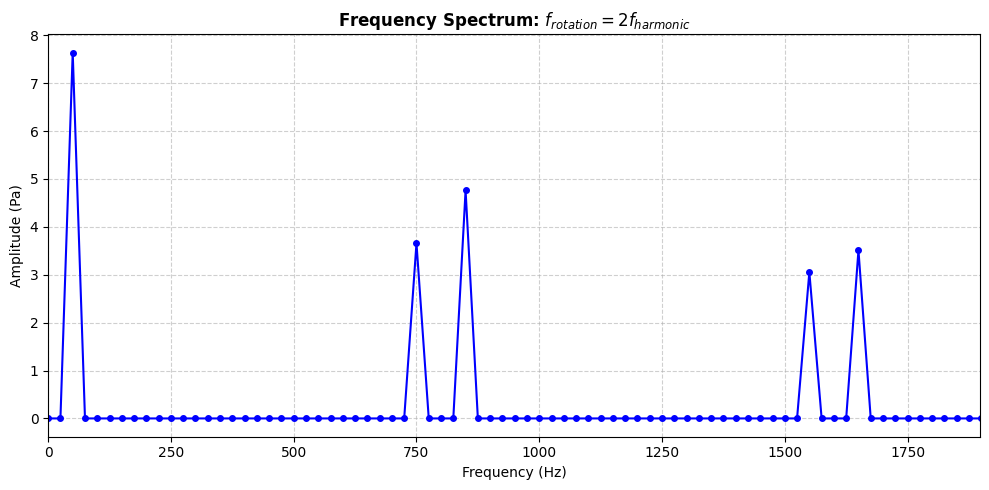

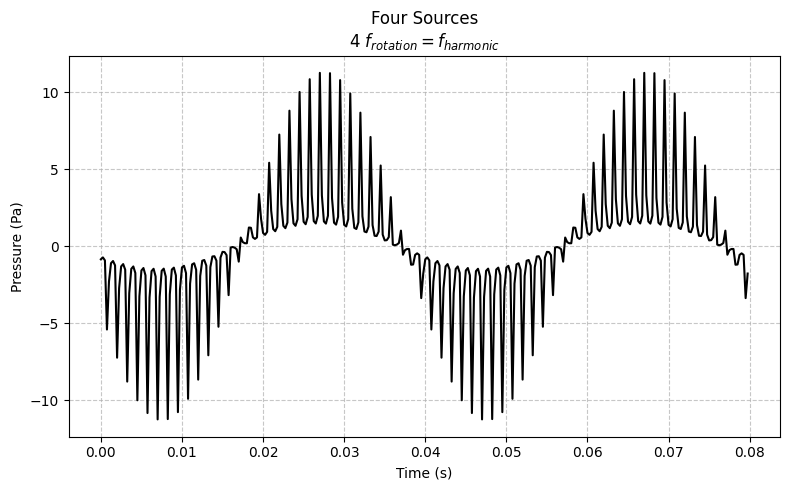

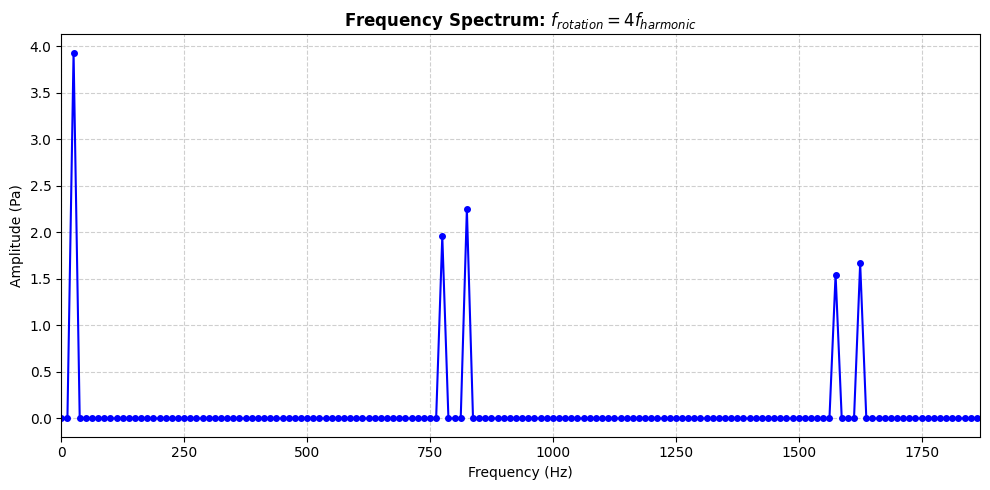

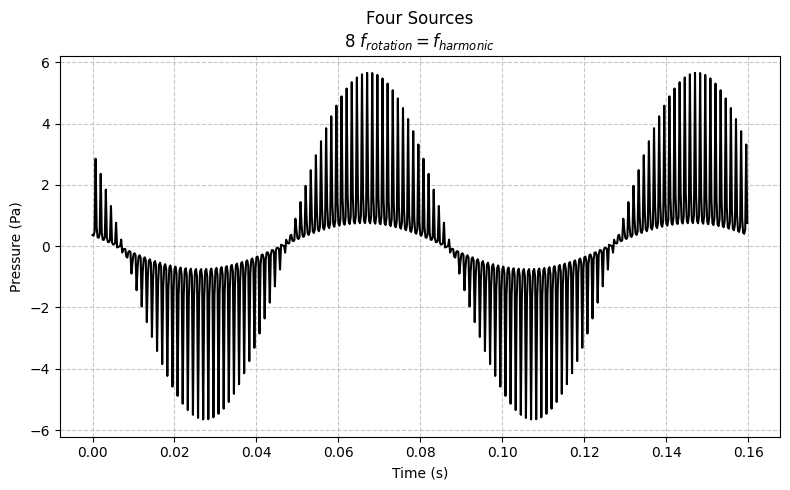

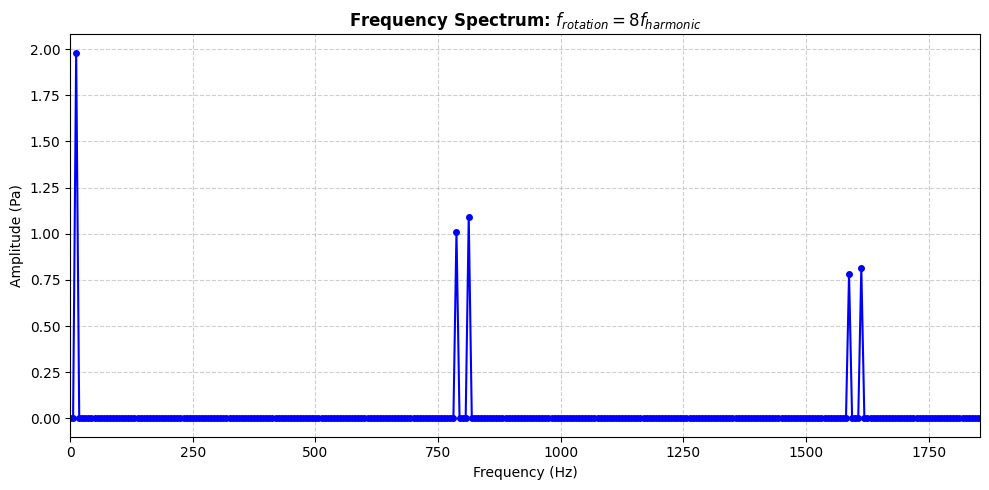

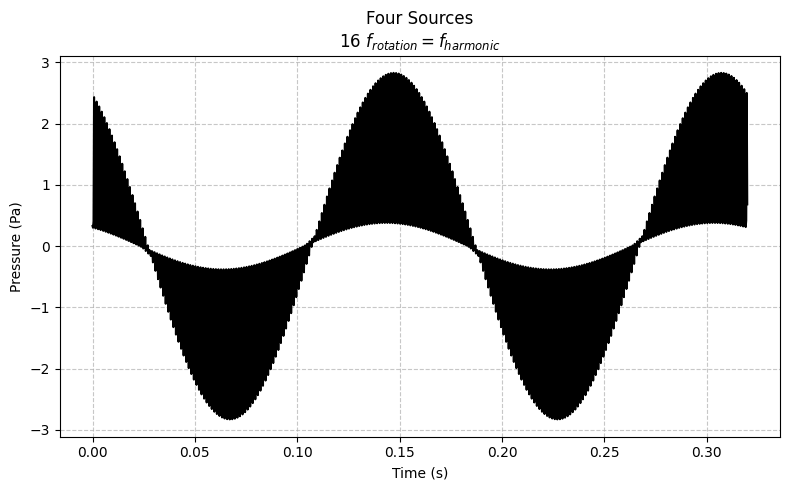

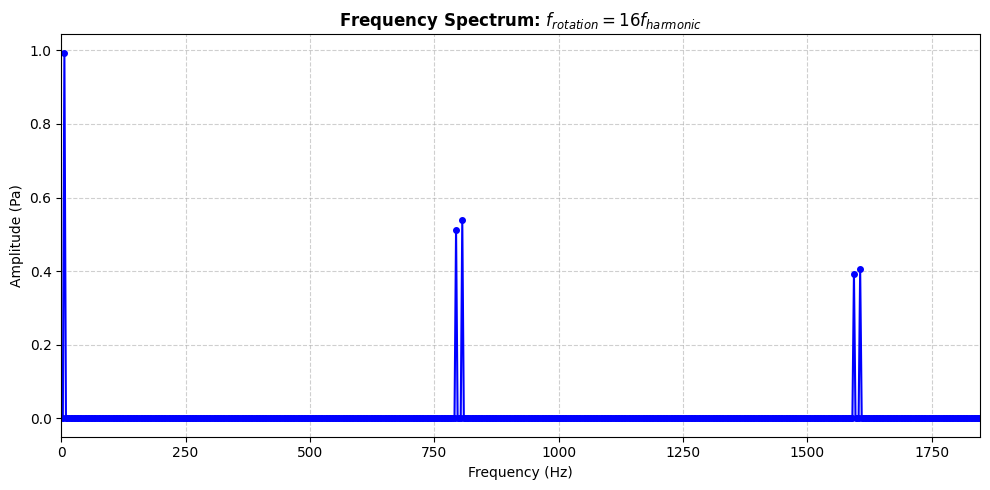

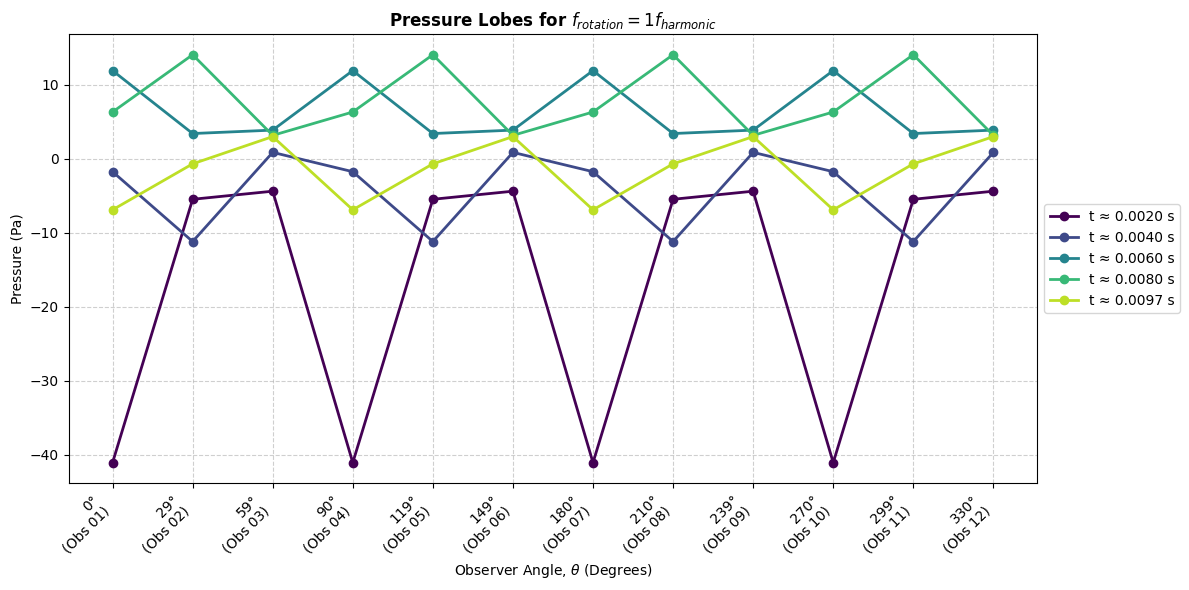

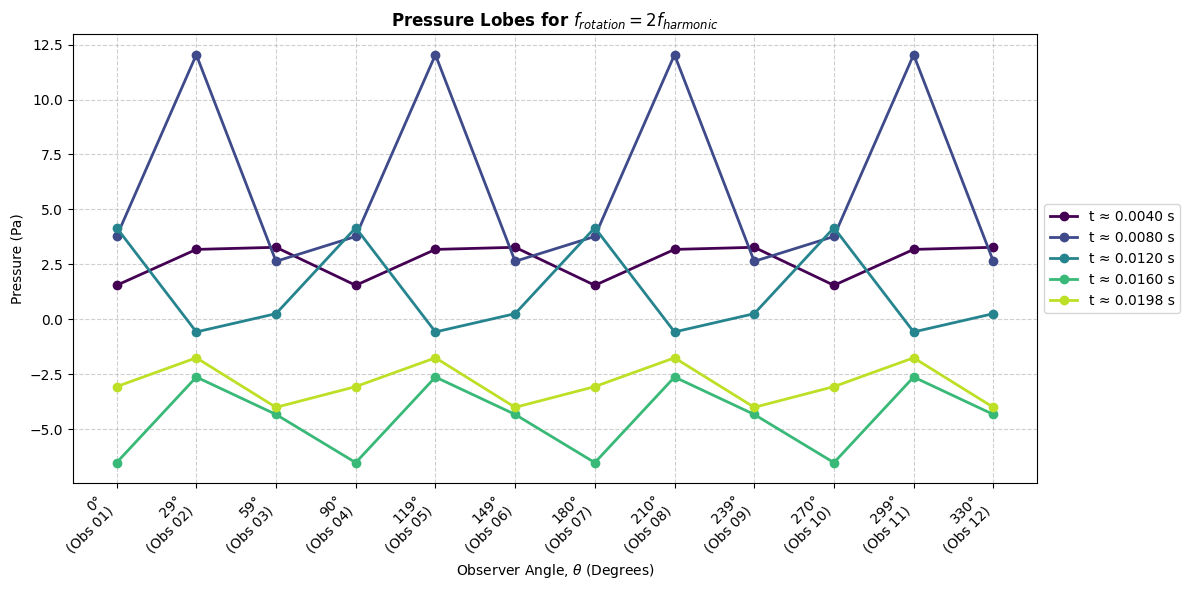

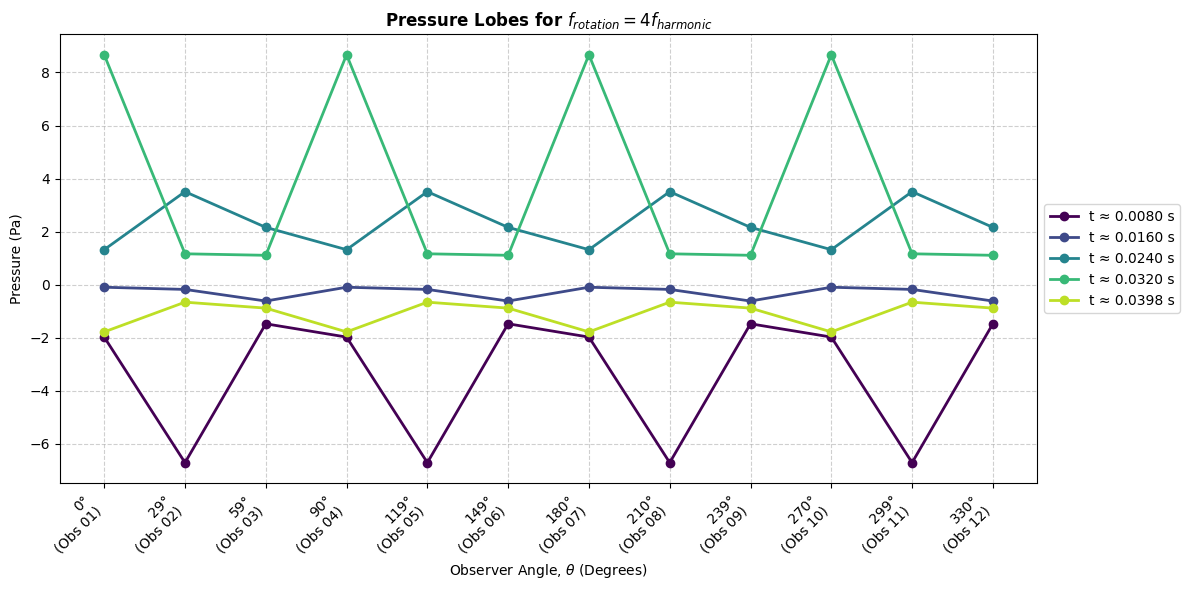

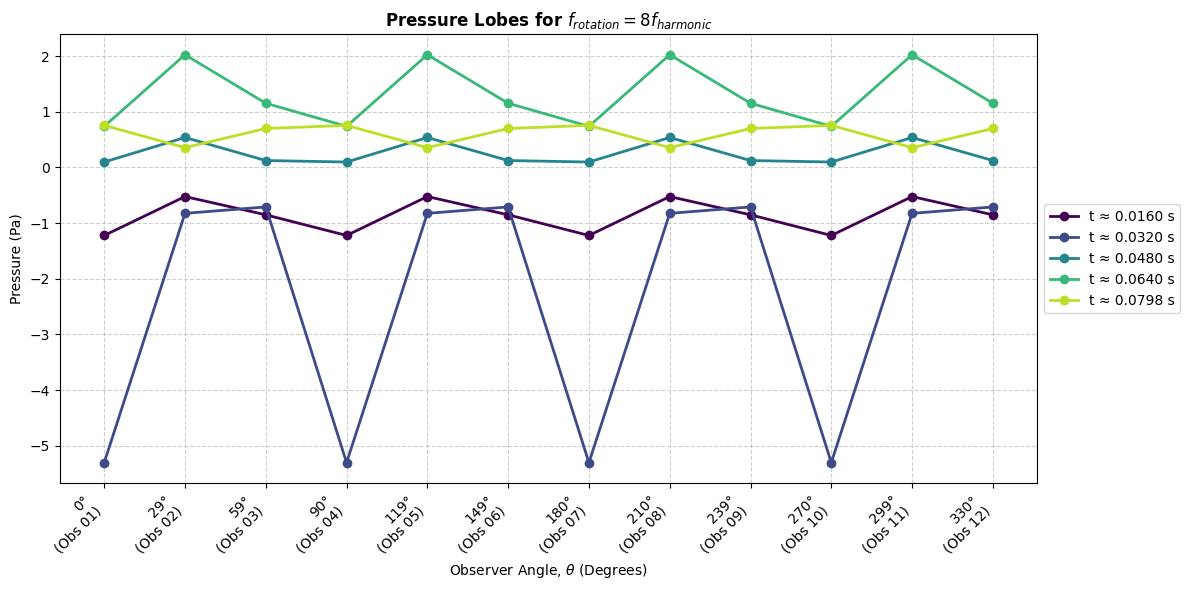

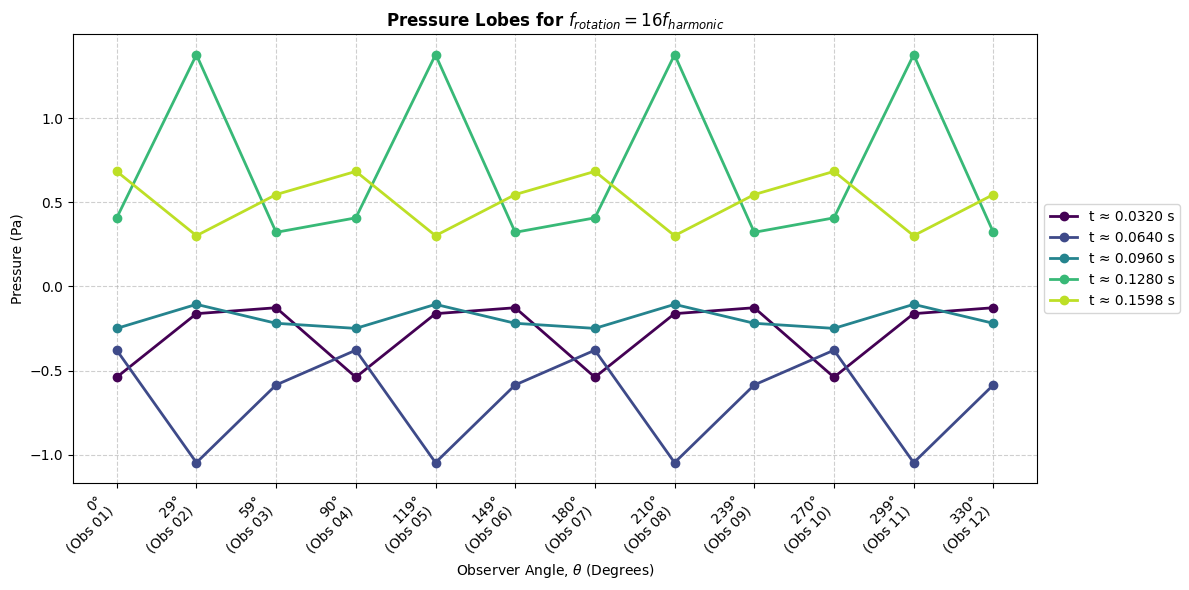

In [14]:
filepath = Path('data_260701/rot_mono_8src_00M_100Hz/')
freqs = (100, 50, 25, 12, 6)

data = [FWHDataset(filepath=filepath / f'ana_rot_{i}Hz_obs01.dat') for i in freqs]

ratios = [1, 2, 4, 8, 16]

for i, dataset in enumerate(data):
    ratio = ratios[i]
    
    if ratio == 1:
        title_str = ("Four Sources" + "\n" + r"$f_{rotation} = f_{harmonic}$")
        fft_title = r"Frequency Spectrum: $f_{rotation} = f_{harmonic}$"
    else:
        title_str = ("Four Sources" + "\n" rf"{ratio} $f_{{rotation}} = f_{{harmonic}}$")
        fft_title = rf"Frequency Spectrum: $f_{{rotation}} = {ratio} f_{{harmonic}}$"
        
    FWHPlotter.plot_pressure(dataset, ref_col='P_obs', title=title_str, legend=False)
    fft(dataset, col='P_obs', title=fft_title)

for i in freqs:
    obs_files = sorted(filepath.glob(f"ana_rot_{i}Hz_obs*.dat"))
    datasets = [FWHDataset(filepath=f) for f in obs_files]

    t_half = datasets[0].data['Time'].max() / 2

    snapshot_times = np.linspace(t_half/5, t_half
                                 , num=5)

    FWHPlotter.plot_directivity_snapshot(
        datasets=datasets, 
        target_times=snapshot_times, 
        col='P_obs',
        is_polar=False,
        title=f"Pressure Lobes for $f_{{rotation}} = {int(100/i)} f_{{harmonic}}$"
    )

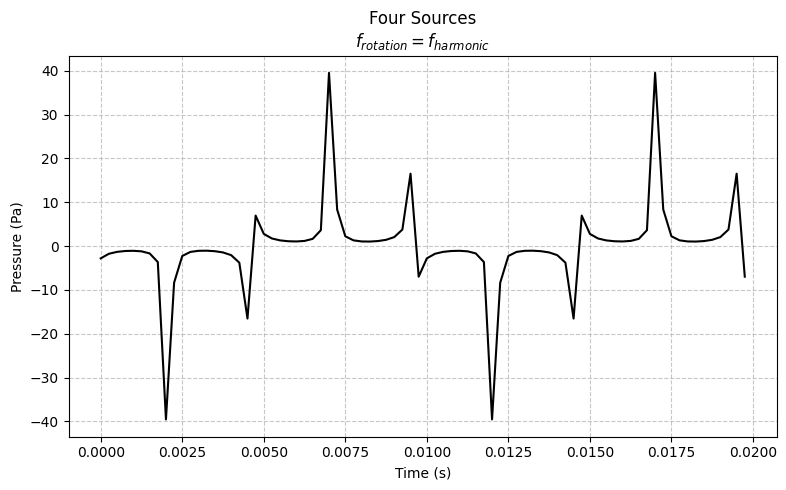

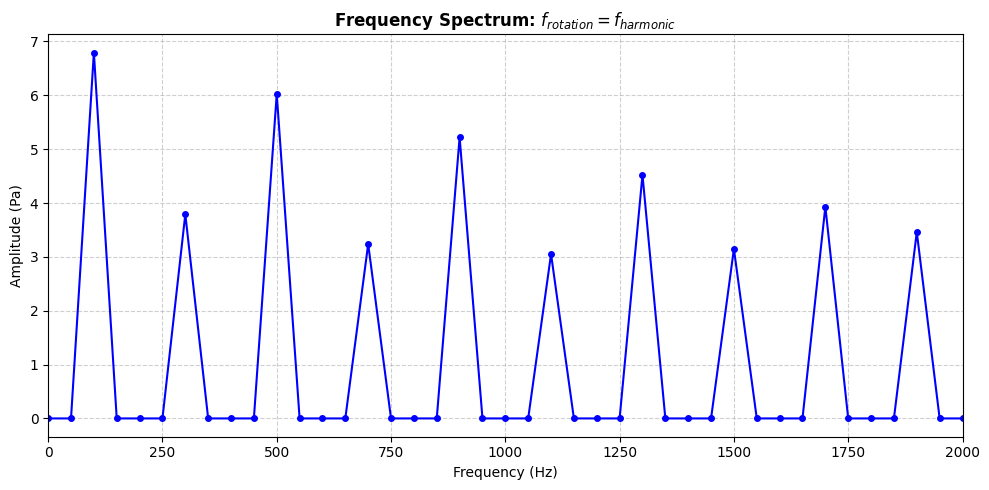

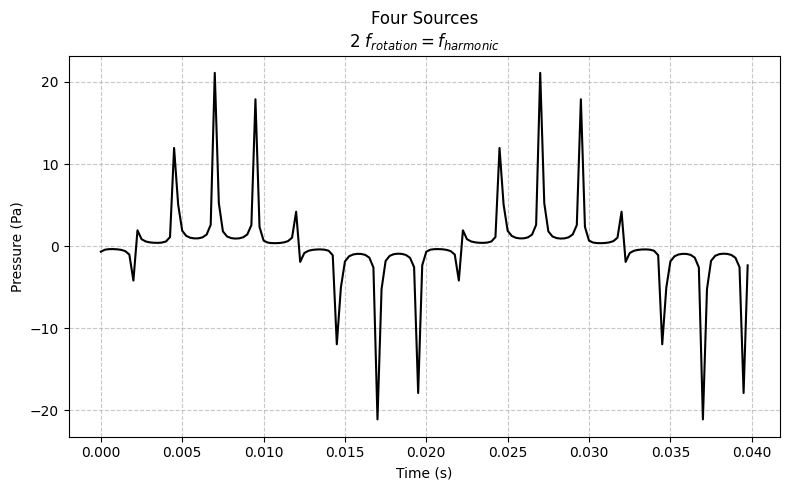

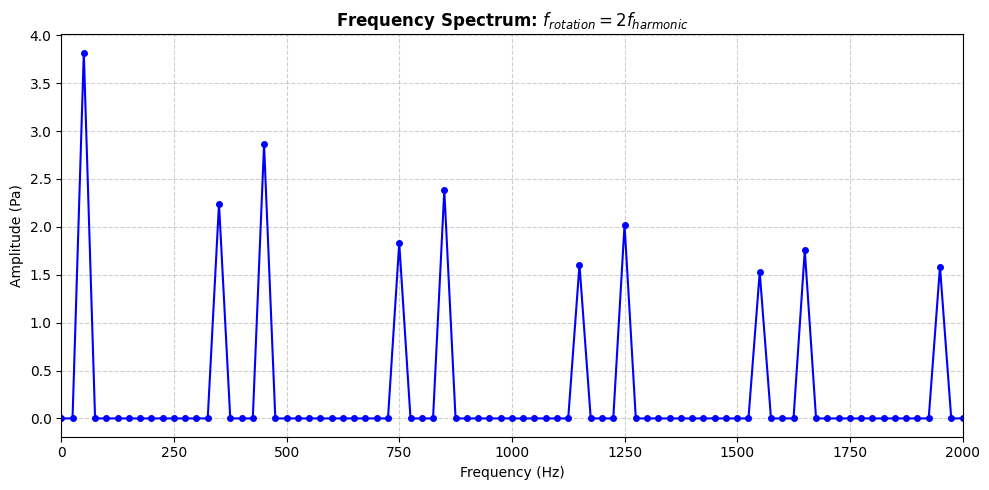

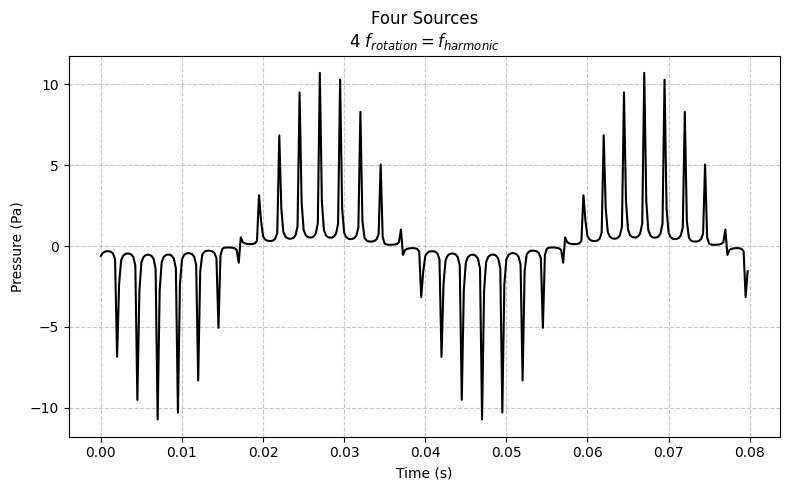

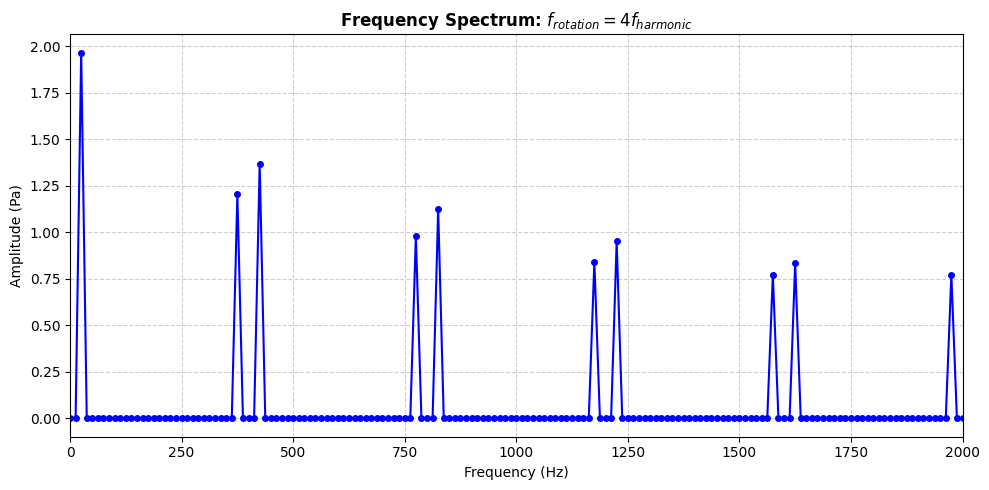

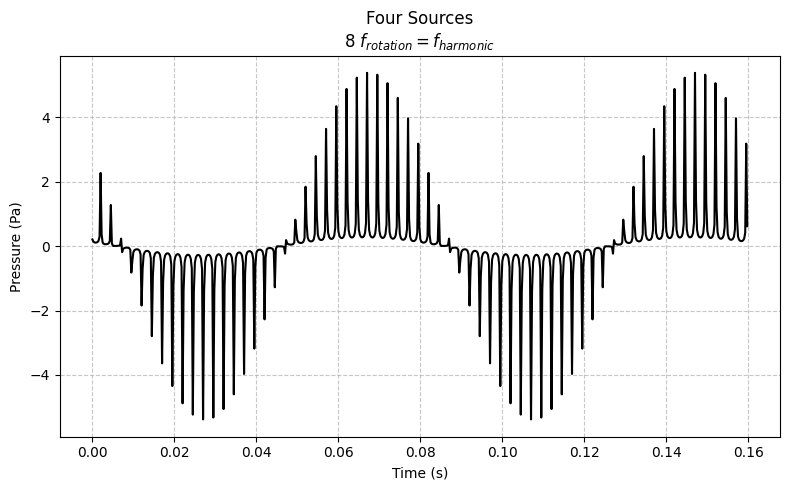

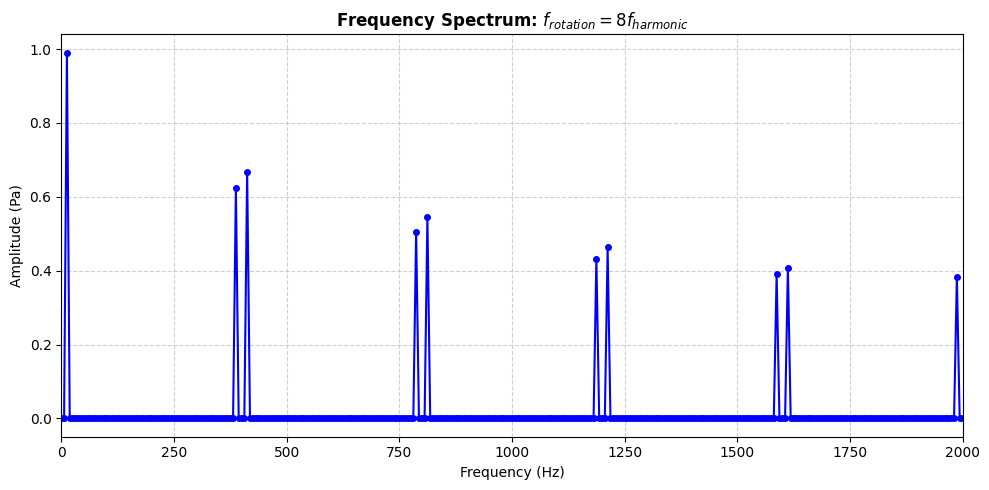

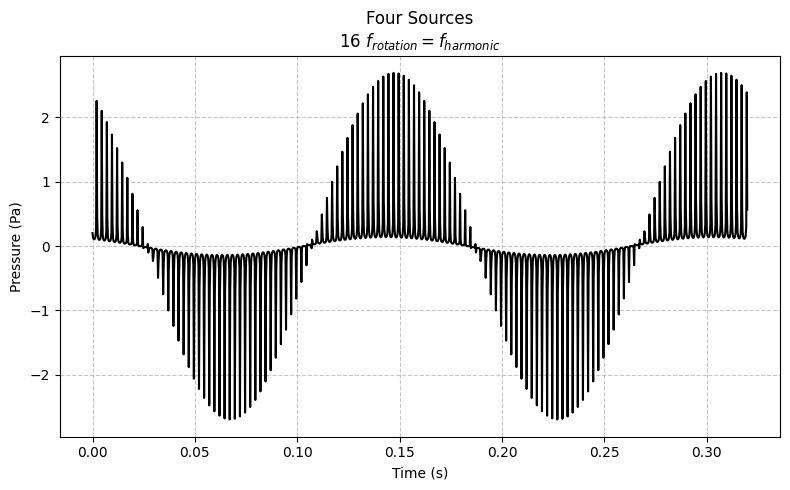

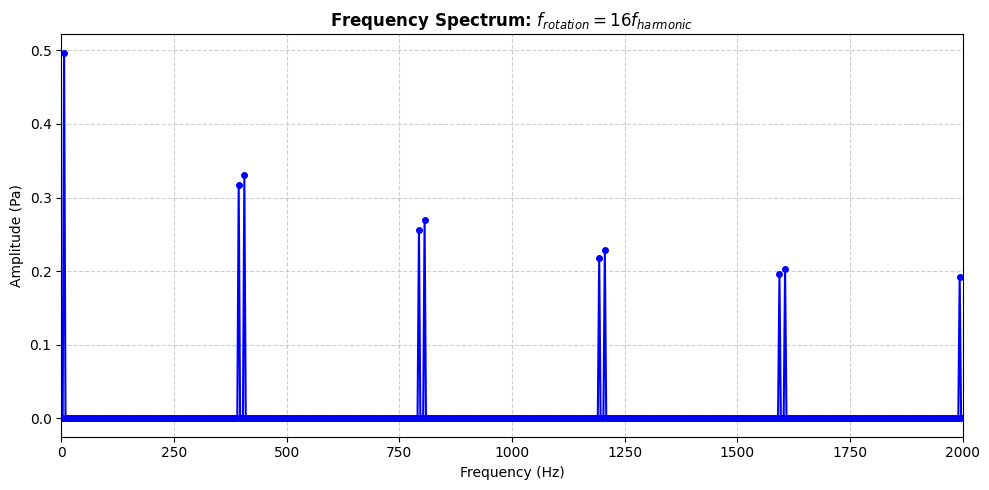

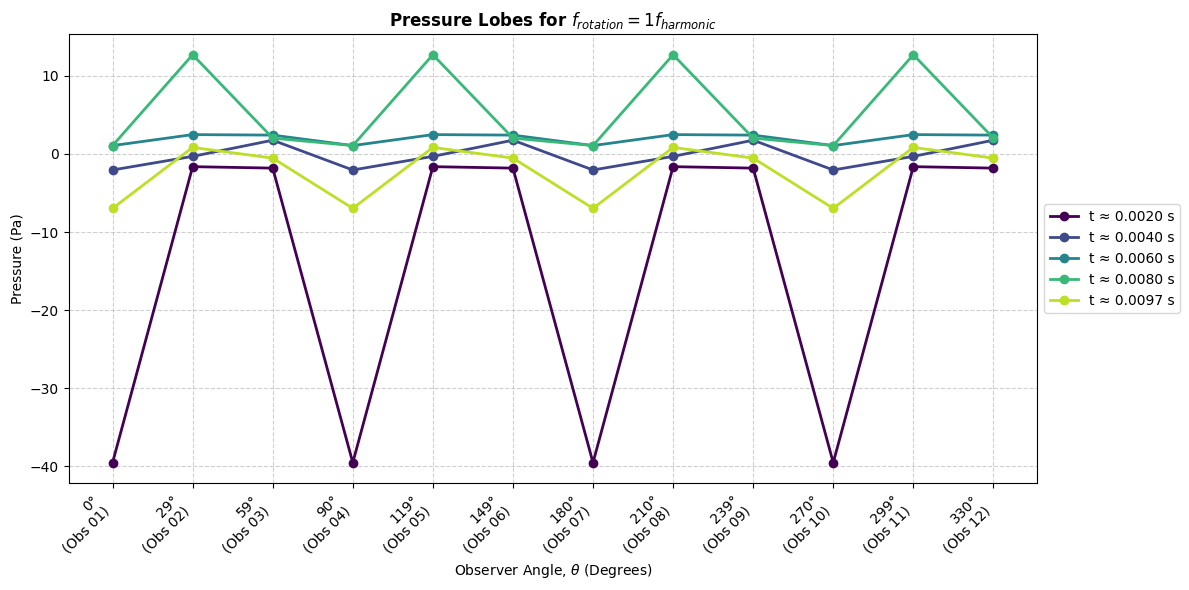

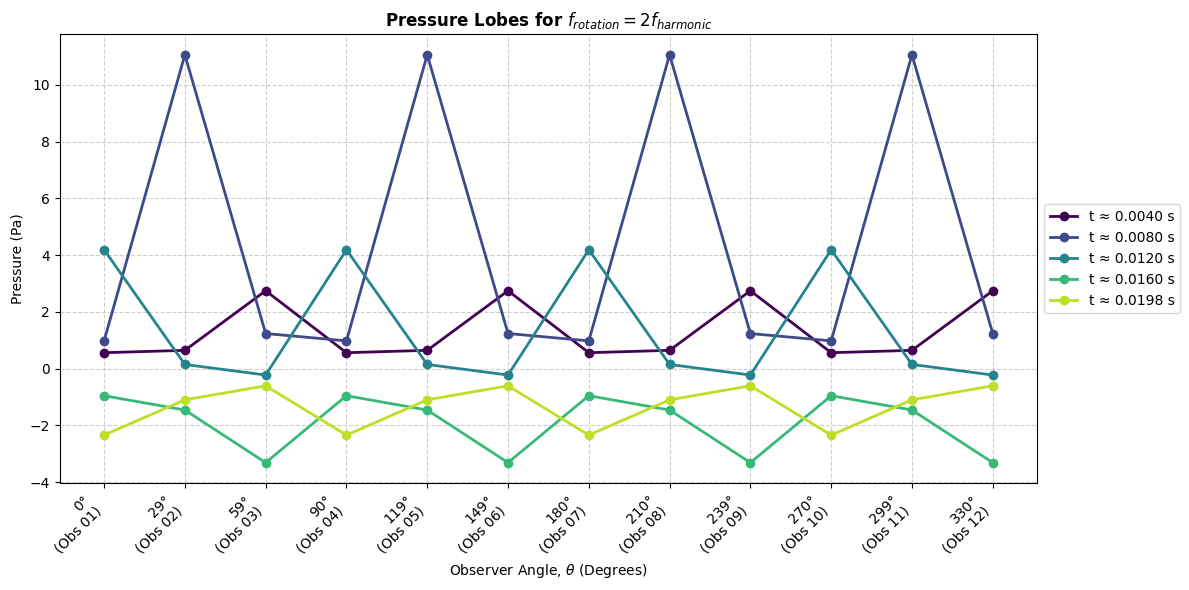

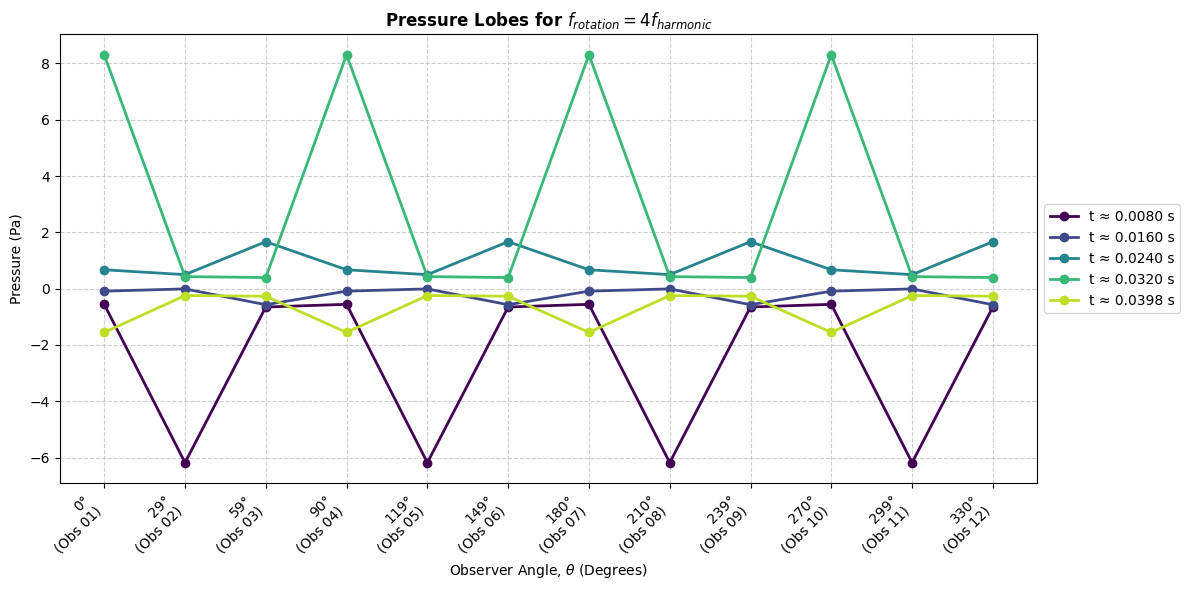

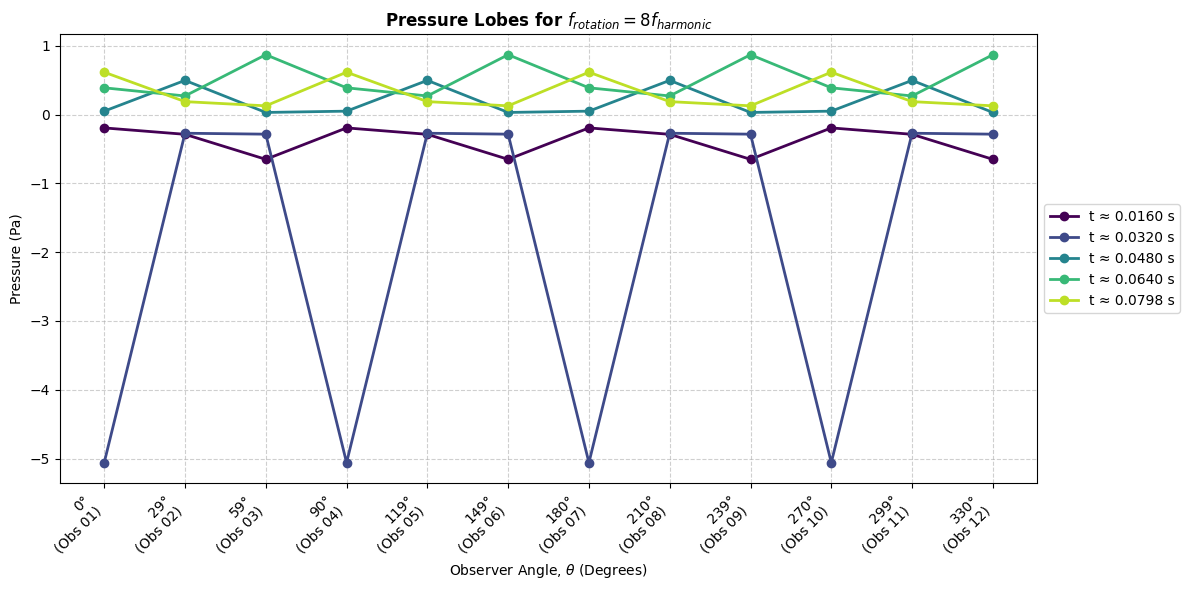

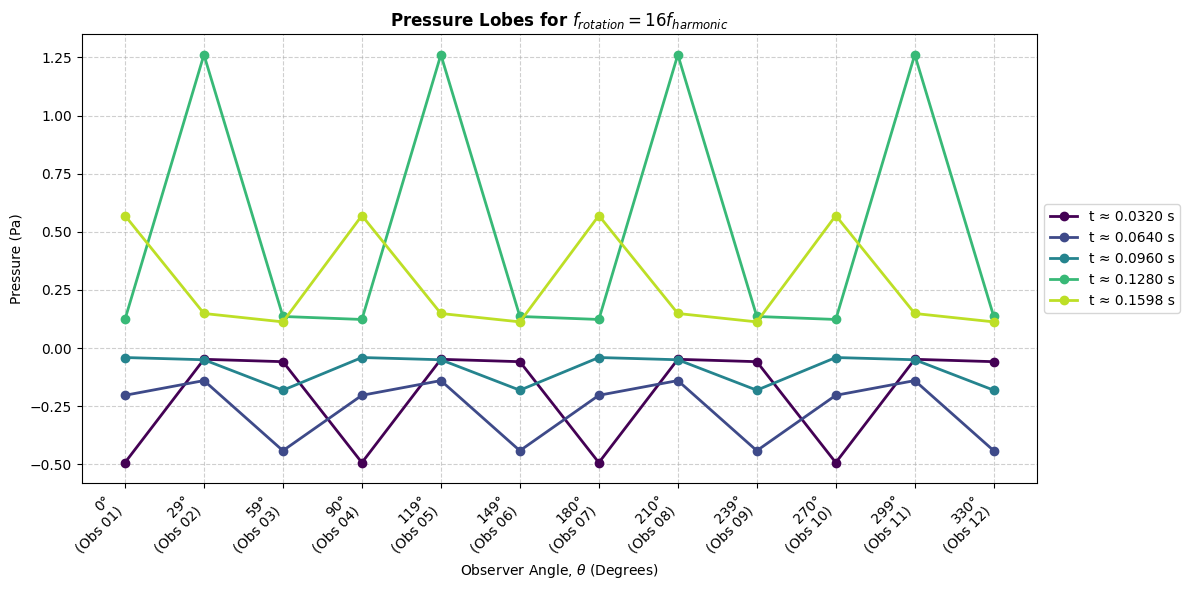

In [15]:
filepath = Path('data_260701/rot_mono_4src_00M_100Hz/')
freqs = (100, 50, 25, 12, 6)
observers = ['01', '02', '03', '04', '05', '06', '07', '08', '09', '10', '11', '12']
obs = 1
obs_id = observers[obs - 1]
data = [FWHDataset(filepath=filepath / f'ana_rot_{i}Hz_obs{obs_id}.dat') for i in freqs]

ratios = [1, 2, 4, 8, 16]

for i, dataset in enumerate(data):
    ratio = ratios[i]
    
    if ratio == 1:
        title_str = ("Four Sources" + "\n" + r"$f_{rotation} = f_{harmonic}$")
        fft_title = r"Frequency Spectrum: $f_{rotation} = f_{harmonic}$"
    else:
        title_str = ("Four Sources" + "\n" rf"{ratio} $f_{{rotation}} = f_{{harmonic}}$")
        fft_title = rf"Frequency Spectrum: $f_{{rotation}} = {ratio} f_{{harmonic}}$"
        
    FWHPlotter.plot_pressure(dataset, ref_col='P_obs', title=title_str, legend=False)
    fft(dataset, col='P_obs', title=fft_title)

for i in freqs:
    obs_files = sorted(filepath.glob(f"ana_rot_{i}Hz_obs*.dat"))
    datasets = [FWHDataset(filepath=f) for f in obs_files]

    t_half = datasets[0].data['Time'].max() / 2

    snapshot_times = np.linspace(t_half/5, t_half
                                 , num=5)

    FWHPlotter.plot_directivity_snapshot(
        datasets=datasets, 
        target_times=snapshot_times, 
        col='P_obs',
        is_polar=False,
        title=f"Pressure Lobes for $f_{{rotation}} = {int(100/i)} f_{{harmonic}}$"
    )

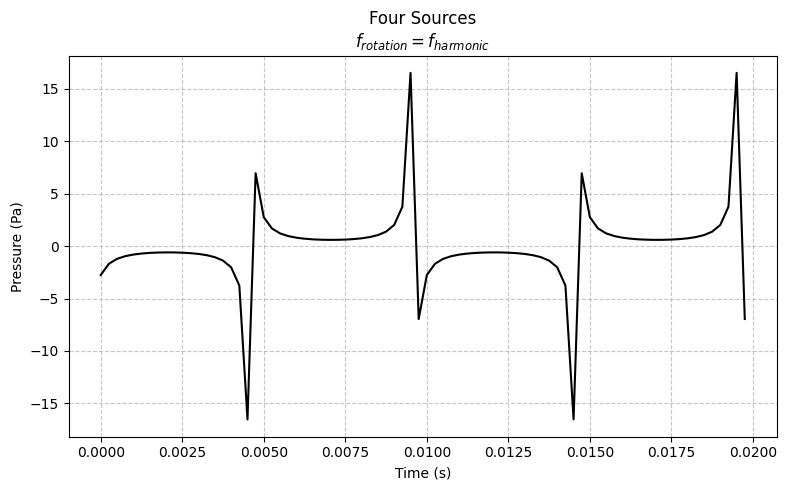

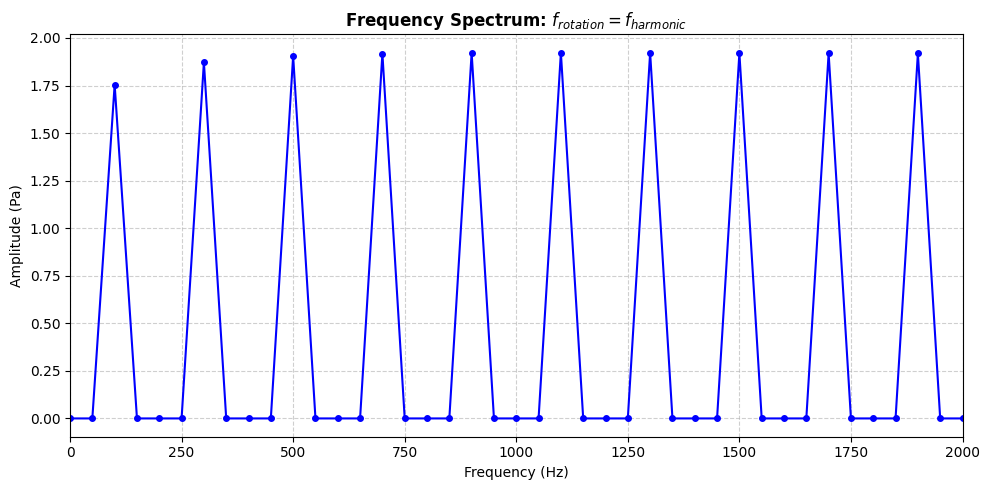

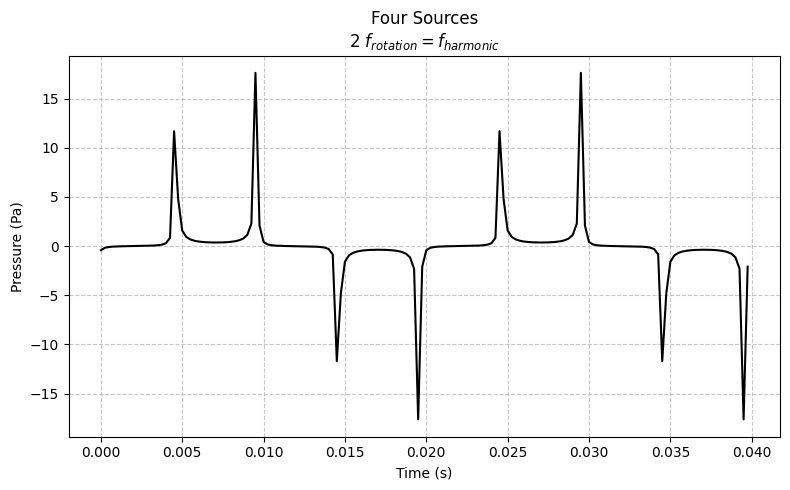

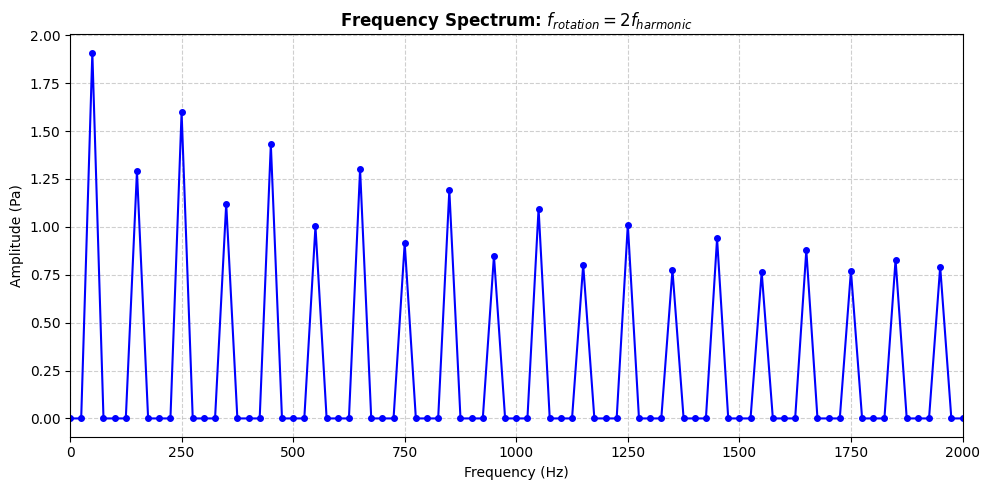

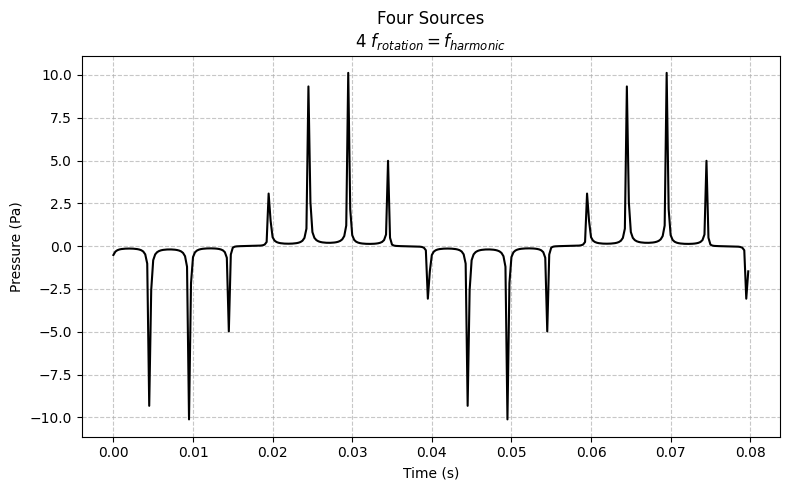

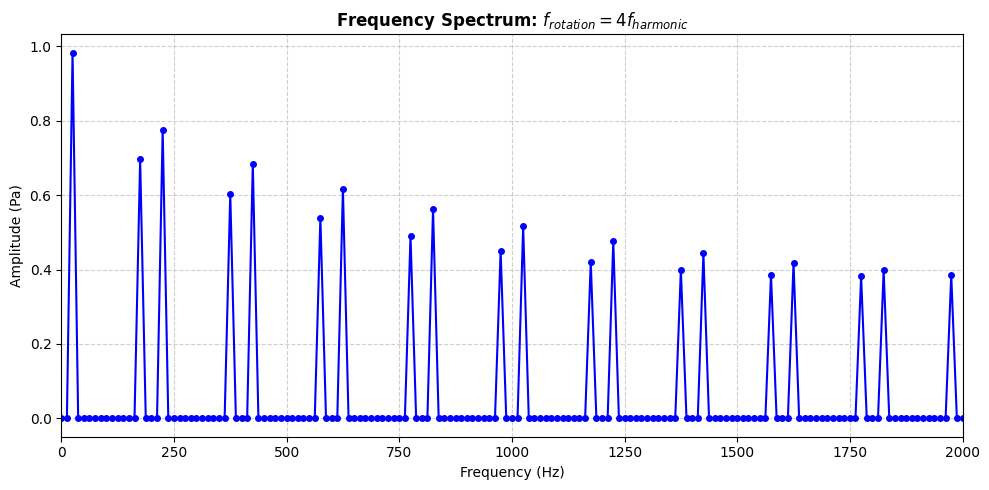

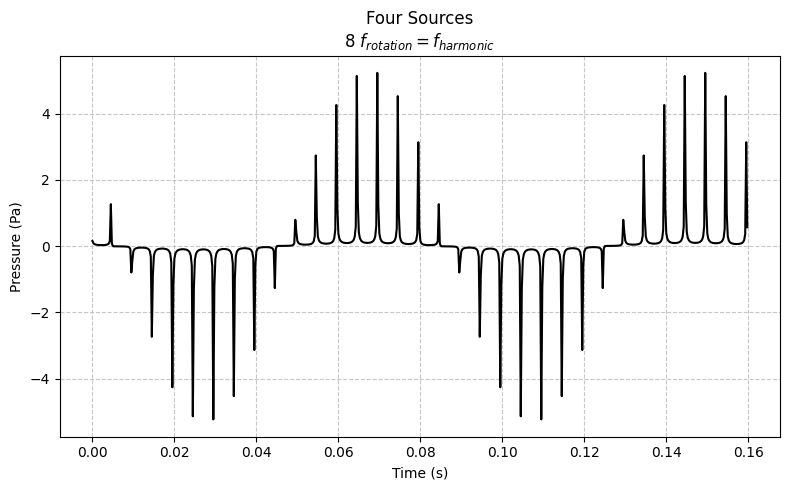

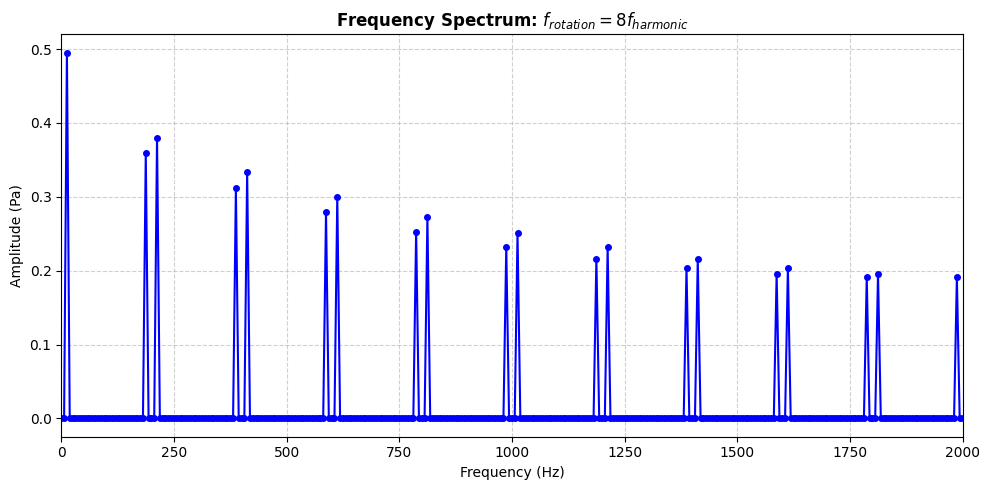

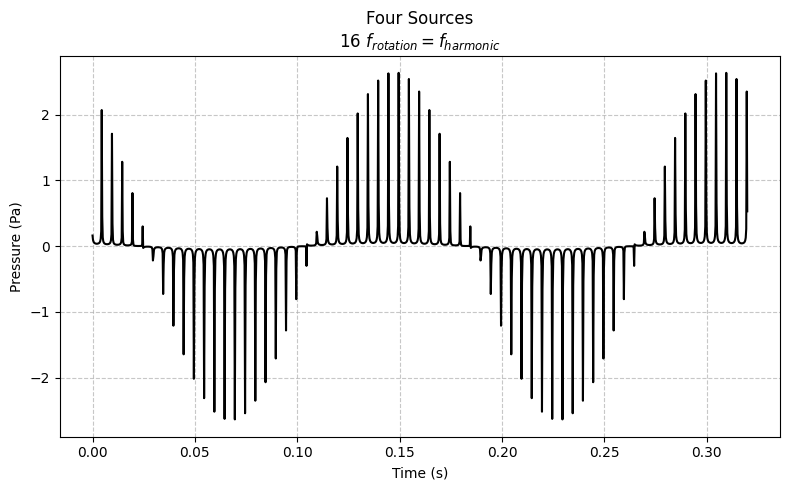

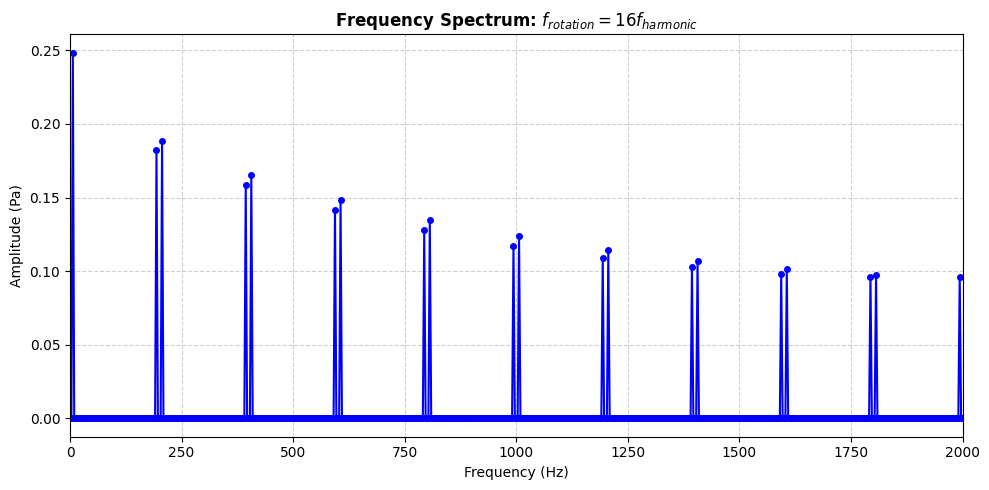

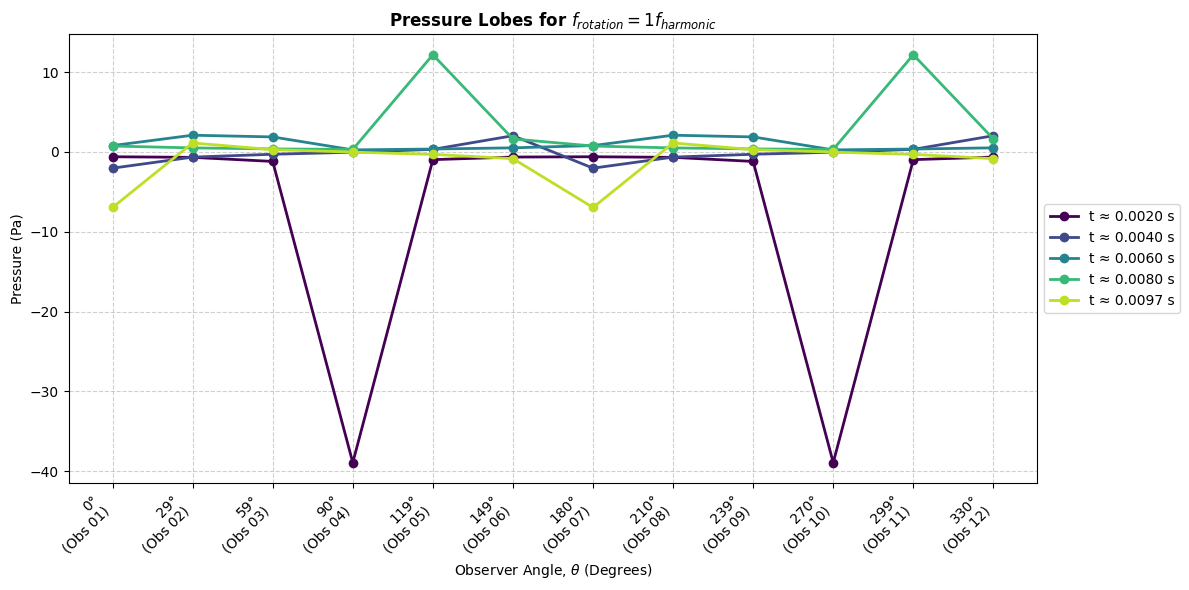

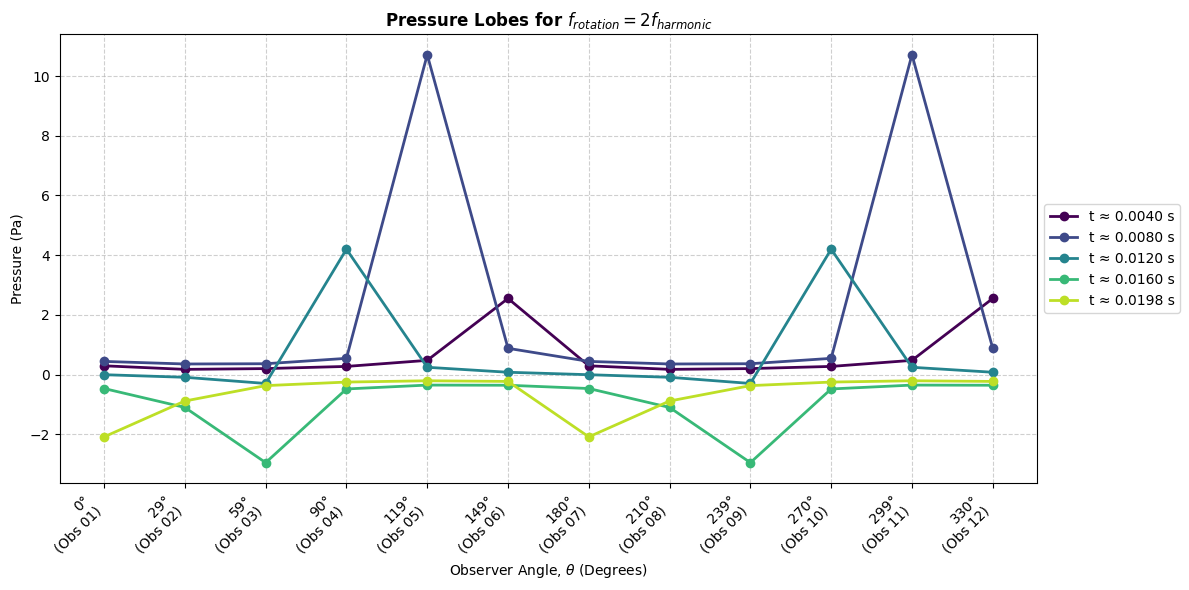

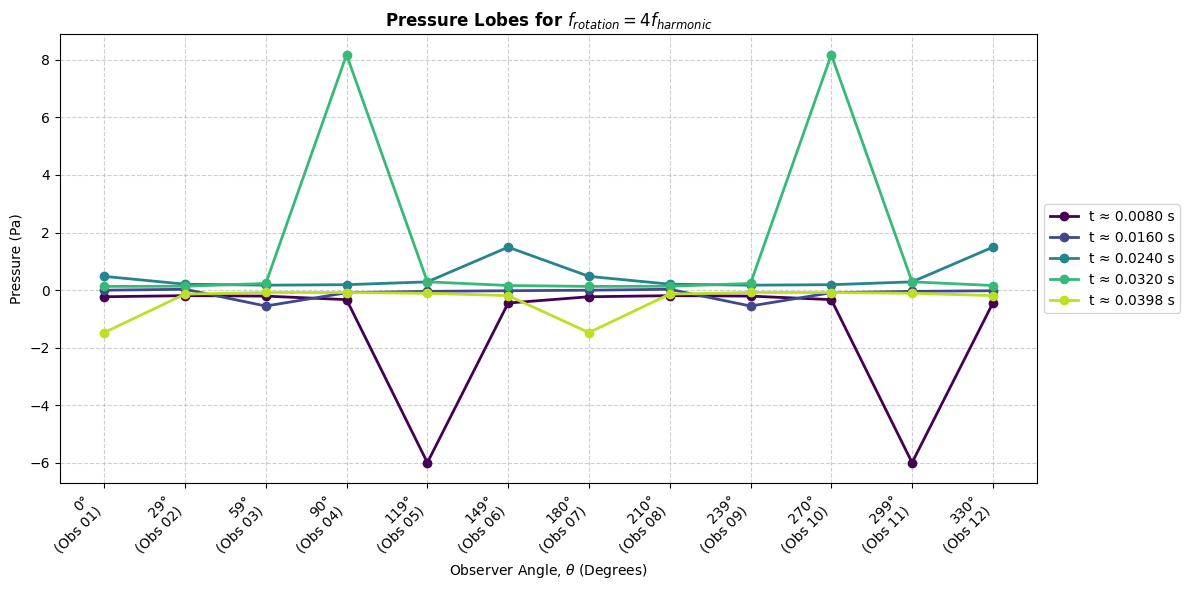

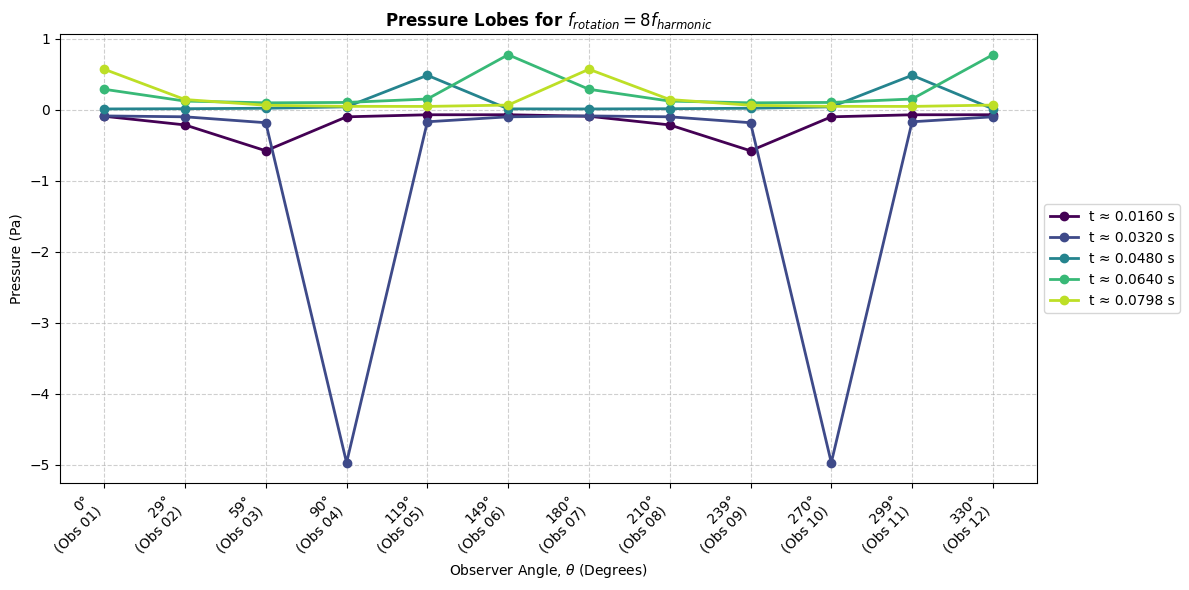

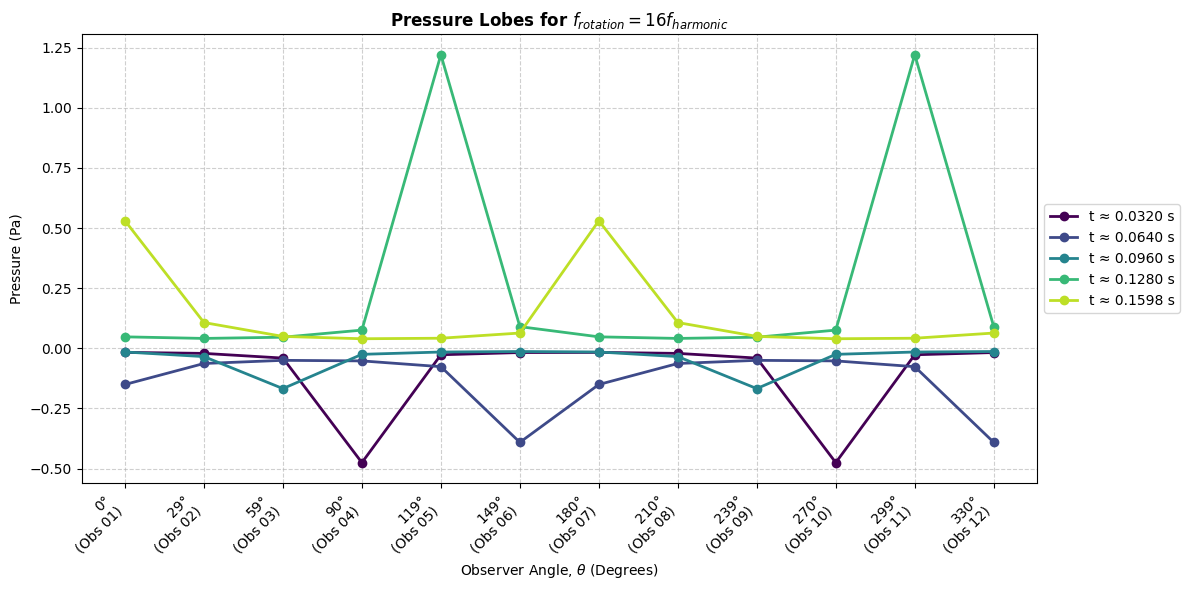

In [16]:
filepath = Path('data_260701/rot_mono_2src_00M_100Hz/')
freqs = (100, 50, 25, 12, 6)

data = [FWHDataset(filepath=filepath / f'ana_rot_{i}Hz_obs01.dat') for i in freqs]

ratios = [1, 2, 4, 8, 16]

for i, dataset in enumerate(data):
    ratio = ratios[i]
    
    if ratio == 1:
        title_str = ("Four Sources" + "\n" + r"$f_{rotation} = f_{harmonic}$")
        fft_title = r"Frequency Spectrum: $f_{rotation} = f_{harmonic}$"
    else:
        title_str = ("Four Sources" + "\n" rf"{ratio} $f_{{rotation}} = f_{{harmonic}}$")
        fft_title = rf"Frequency Spectrum: $f_{{rotation}} = {ratio} f_{{harmonic}}$"
        
    FWHPlotter.plot_pressure(dataset, ref_col='P_obs', title=title_str, legend=False)
    fft(dataset, col='P_obs', title=fft_title)

for i in freqs:
    obs_files = sorted(filepath.glob(f"ana_rot_{i}Hz_obs*.dat"))
    datasets = [FWHDataset(filepath=f) for f in obs_files]

    t_half = datasets[0].data['Time'].max() / 2

    snapshot_times = np.linspace(t_half/5, t_half
                                 , num=5)

    FWHPlotter.plot_directivity_snapshot(
        datasets=datasets, 
        target_times=snapshot_times, 
        col='P_obs',
        is_polar=False,
        title=f"Pressure Lobes for $f_{{rotation}} = {int(100/i)} f_{{harmonic}}$"
    )

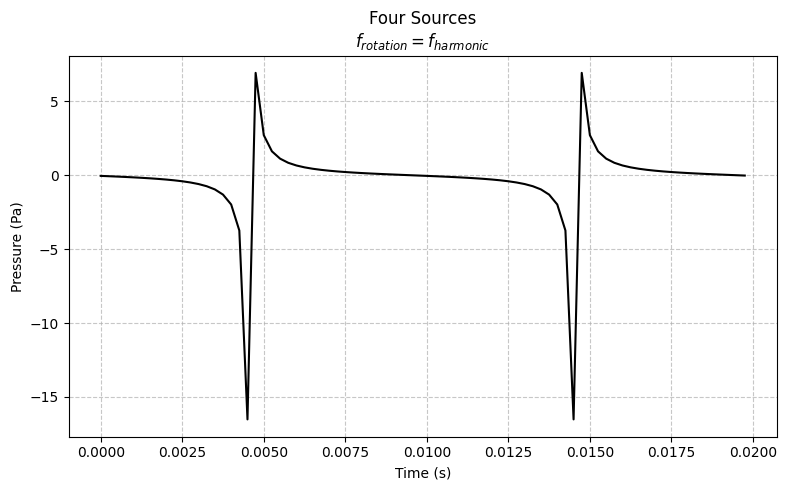

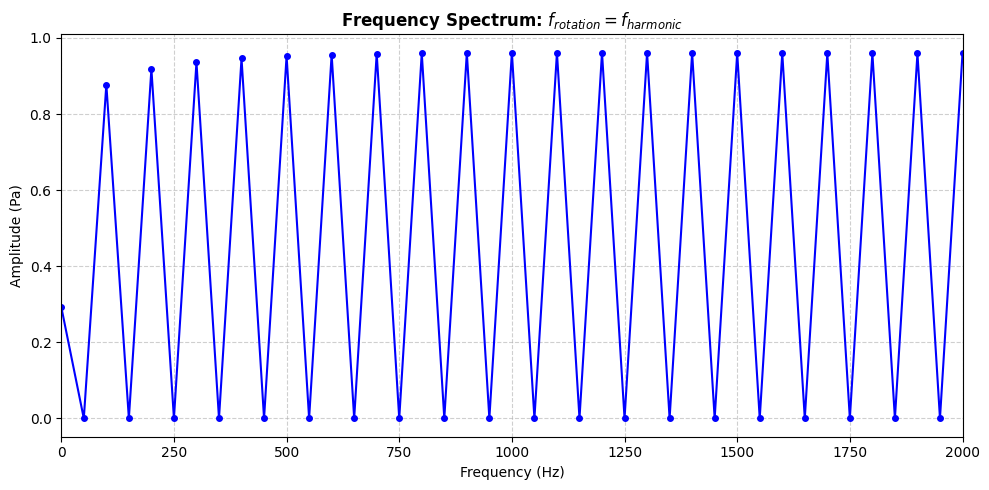

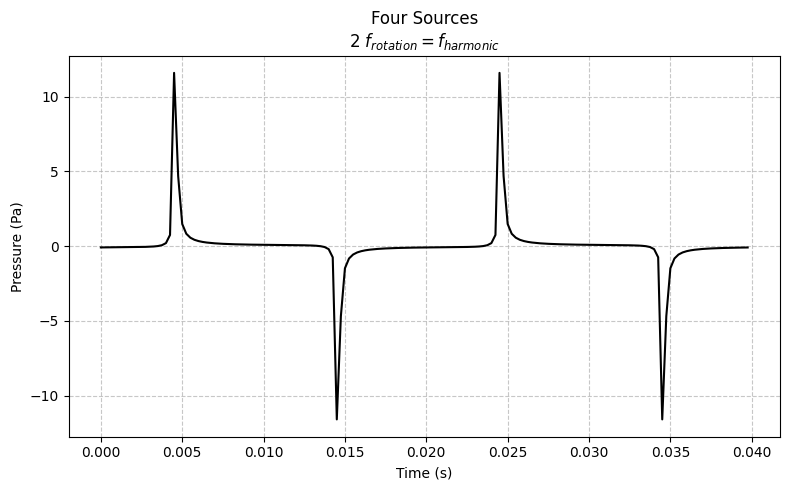

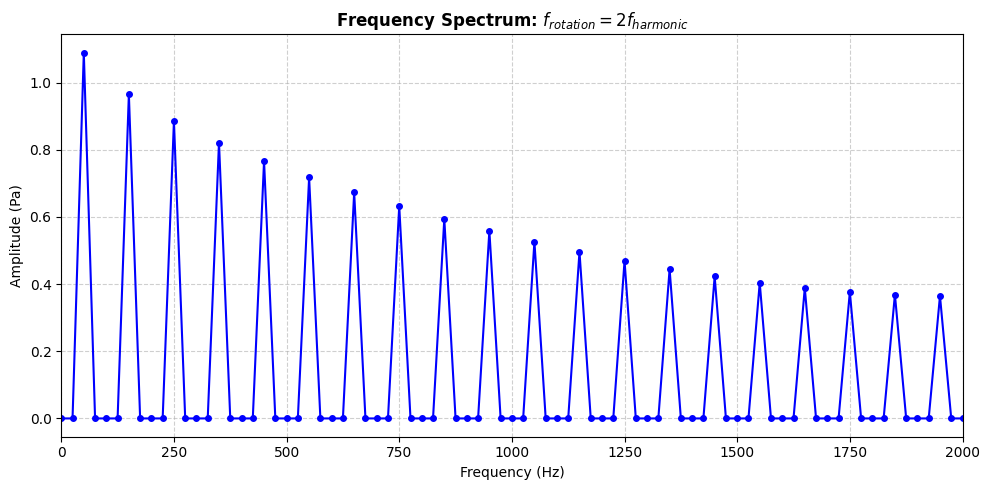

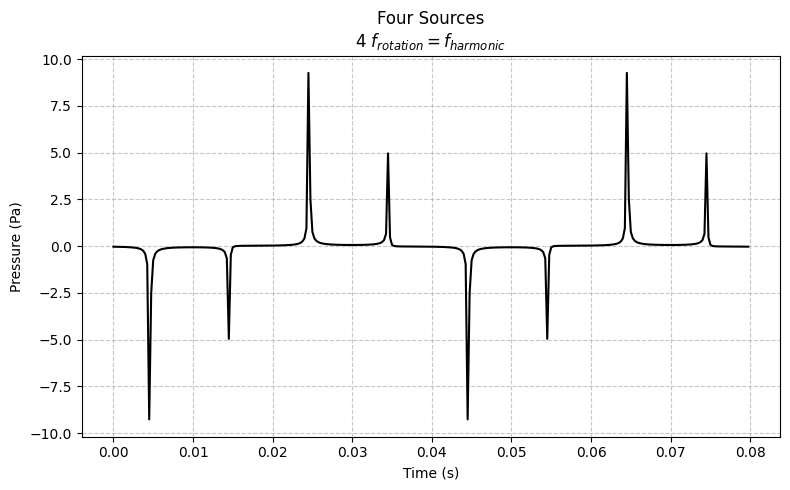

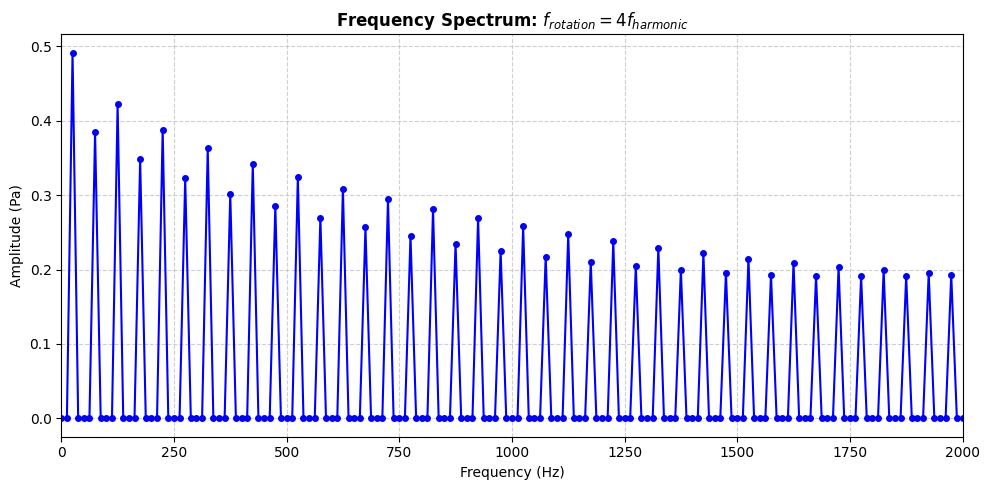

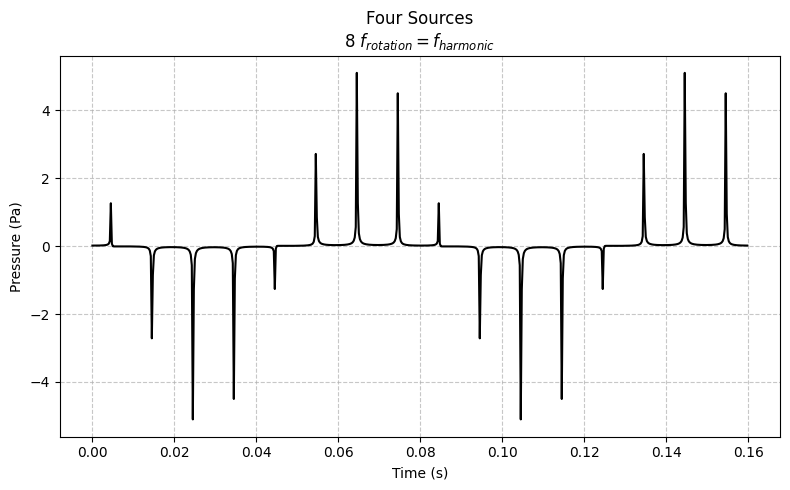

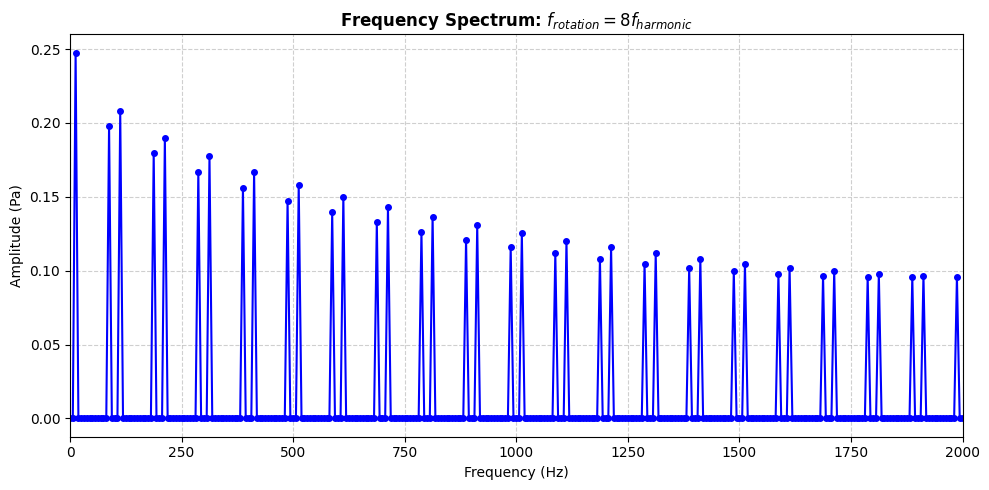

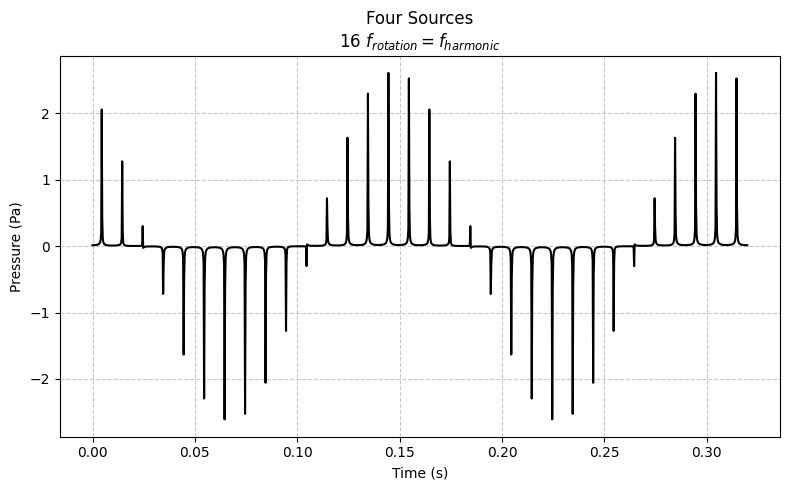

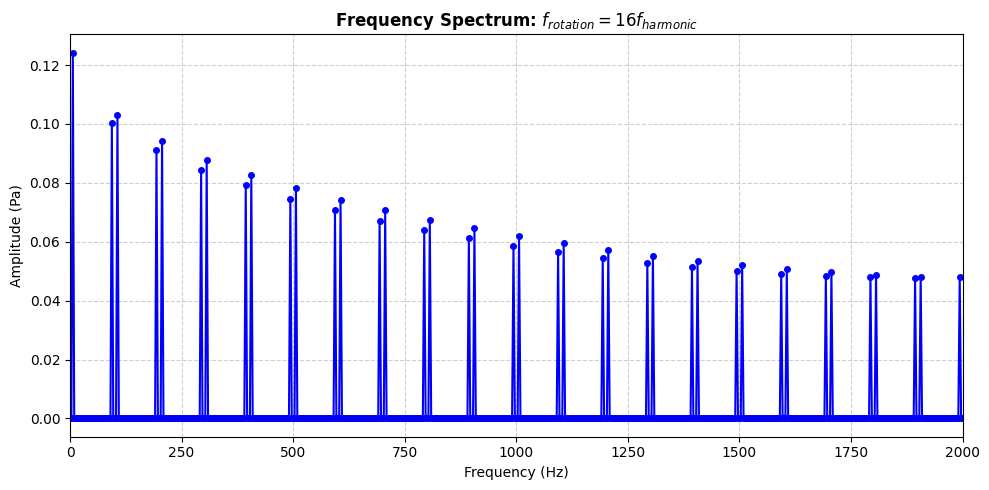

In [17]:
### Fine, dt = 1 / (P * f_rot)
# everything in 100 Hz folder

filepath = Path('data_260630/rot_mono_00M_100Hz/')
freqs = (100, 50, 25, 12, 6)

data = [FWHDataset(filepath=filepath / f'ana_rot_{i}Hz.dat') for i in freqs]

ratios = [1, 2, 4, 8, 16]

for i, dataset in enumerate(data):
    ratio = ratios[i]
    
    if ratio == 1:
        title_str = ("Four Sources" + "\n" + r"$f_{rotation} = f_{harmonic}$")
        fft_title = r"Frequency Spectrum: $f_{rotation} = f_{harmonic}$"
    else:
        title_str = ("Four Sources" + "\n" rf"{ratio} $f_{{rotation}} = f_{{harmonic}}$")
        fft_title = rf"Frequency Spectrum: $f_{{rotation}} = {ratio} f_{{harmonic}}$"
        
    FWHPlotter.plot_pressure(dataset, ref_col='P_obs', title=title_str, legend=False)
    fft(dataset, col='P_obs', title=fft_title)

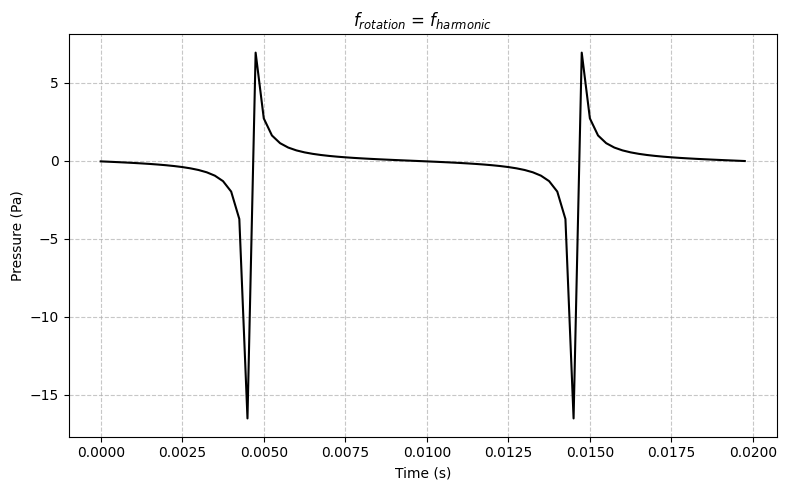

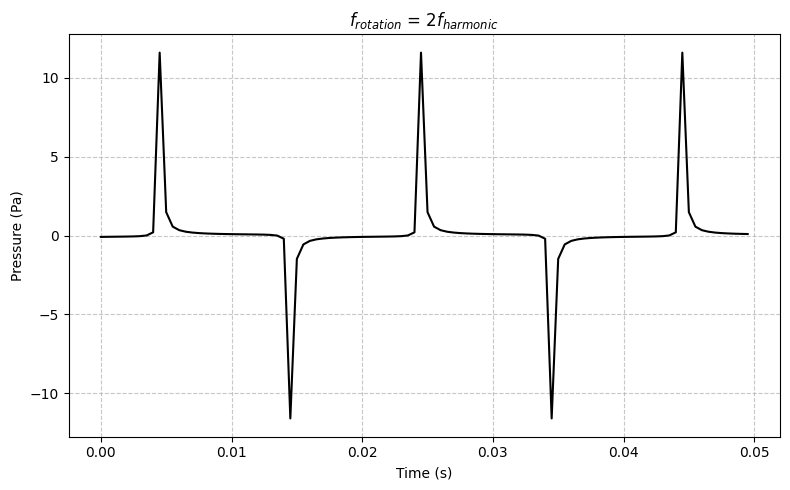

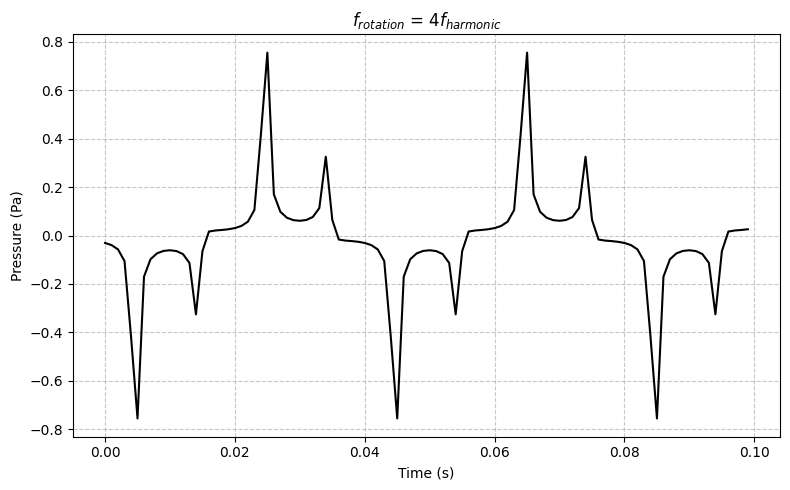

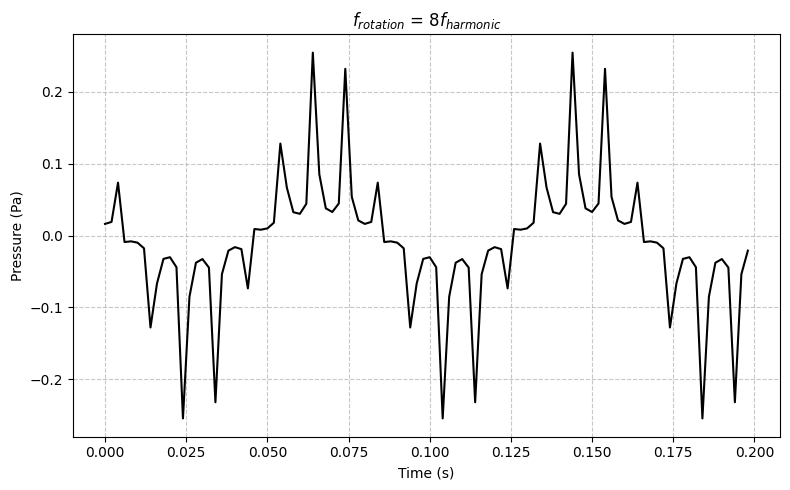

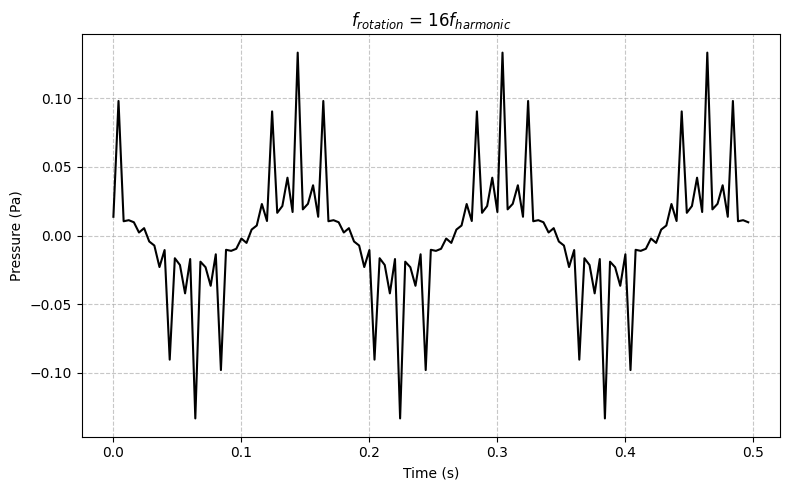

In [4]:
# Coarse, dt = 1 / (P * fsource)
# everything in individual folders

filepath = Path('data_260630/rot_mono_00M_100Hz/')
analytical = FWHDataset(filepath / 'ana_rot_100Hz.dat')
FWHPlotter.plot_pressure(analytical, ref_col='P_obs', title=f"$f_{{rotation}}$ = $f_{{harmonic}}$", legend=False)

filepath = Path('data_260630/rot_mono_00M_50Hz/')
analytical = FWHDataset(filepath / 'ana_rot_100Hz.dat')
FWHPlotter.plot_pressure(analytical, ref_col='P_obs', title=f"$f_{{rotation}}$ = 2$f_{{harmonic}}$", legend=False)

filepath = Path('data_260630/rot_mono_00M_25Hz/')
analytical = FWHDataset(filepath / 'ana_rot_100Hz.dat')
FWHPlotter.plot_pressure(analytical, ref_col='P_obs', title=f"$f_{{rotation}}$ = 4$f_{{harmonic}}$", legend=False)

filepath = Path('data_260630/rot_mono_00M_12Hz/')
analytical = FWHDataset(filepath / 'ana_rot_100Hz.dat')
FWHPlotter.plot_pressure(analytical, ref_col='P_obs', title=f"$f_{{rotation}}$ = 8$f_{{harmonic}}$", legend=False)

filepath = Path('data_260630/rot_mono_00M_6Hz/')
analytical = FWHDataset(filepath / 'ana_rot_100Hz.dat')
FWHPlotter.plot_pressure(analytical, ref_col='P_obs', title=f"$f_{{rotation}}$ = 16$f_{{harmonic}}$", legend=False)
